In [1]:
%load_ext autoreload
%autoreload 2

In [2]:
import json
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pvlib
import seaborn as sns
import xarray as xr
from pvlib.location import Location
from pyproj import Transformer

sys.path.append("../..")
from cordex2energy.conversion_energy.pv import (
    NORMALISED_ROOFTOP_PV_CONFIGURATION,
    compute_clearsky_profile,
    generate_clearsky_profiles,
    disaggregate_pv_to_hourly,
    disaggregate_pv_to_hourly_pd,
)

sns.set_style("whitegrid", {"grid.color": ".93"})


ERROR 1: PROJ: proj_create_from_database: Open of /home/yhaddad/.conda/envs/bias_correction_2024/share/proj failed


In [3]:
paths = json.load(open("../../paths_so4.json"))

path_data_analysis = Path(paths["path_data_analysis"])
path_data_processed = Path(paths["path_data_processed"])

path_energy_ch = path_data_processed / "energy" / "ch"
path_energy_europe = path_data_processed / "energy" / "europe"

# Functions

In [4]:
azimuths = {"E": 90, "SE": 135, "S": 180, "SW": 225, "W": 270, "N": 0}

# Test

## xarray

In [5]:
climate_model_chain = "CNRM-ALADIN63_CNRM-CERFACS-CNRM-CM5_r1i1p1"
climate_scenario = "rcp85"

In [6]:
# Path mirrors compute_pv.py output structure:
# energy/ch/pv/{model}_{scenario}/pv_{model}_{scenario}.zarr
path_pv = (
    path_energy_ch / "pv"
    / f"{climate_model_chain}_{climate_scenario}"
    / f"pv_{climate_model_chain}_{climate_scenario}.zarr"
)

# The compute script already applies system_loss and normalises by pdc0 (1000 W).
# Output units: W per kWp  →  divide by 1000 to get kW/kWp (capacity factor).
ds_pv = xr.open_zarr(path_pv, chunks="auto")
ds_pv


<xarray.Dataset> Size: 133GB
Dimensions:             (lat: 21, lon: 46, time: 318280)
Coordinates:
  * lat                 (lat) float64 168B 45.85 45.95 46.05 ... 47.75 47.85
  * lon                 (lon) float64 368B 5.95 6.05 6.15 ... 10.25 10.35 10.45
  * time                (time) datetime64[ns] 3MB 1991-01-01T01:30:00 ... 209...
Data variables: (12/54)
    tilt_15_azimuth_E   (time, lat, lon) float64 2GB dask.array<chunksize=(2920, 21, 46), meta=np.ndarray>
    tilt_15_azimuth_N   (time, lat, lon) float64 2GB dask.array<chunksize=(2920, 21, 46), meta=np.ndarray>
    tilt_15_azimuth_S   (time, lat, lon) float64 2GB dask.array<chunksize=(2920, 21, 46), meta=np.ndarray>
    tilt_15_azimuth_SE  (time, lat, lon) float64 2GB dask.array<chunksize=(2920, 21, 46), meta=np.ndarray>
    tilt_15_azimuth_SW  (time, lat, lon) float64 2GB dask.array<chunksize=(2920, 21, 46), meta=np.ndarray>
    tilt_15_azimuth_W   (time, lat, lon) float64 2GB dask.array<chunksize=(2920, 21, 46), meta=np.ndarray>
    ...                  ...
    tilt_90_azimuth_E   (time, lat, lon) float64 2GB dask.array<chunksize=(2920, 21, 46), meta=np.ndarray>
    tilt_90_azimuth_N   (time, lat, lon) float64 2GB dask.array<chunksize=(2920, 21, 46), meta=np.ndarray>
    tilt_90_azimuth_S   (time, lat, lon) float64 2GB dask.array<chunksize=(2920, 21, 46), meta=np.ndarray>
    tilt_90_azimuth_SE  (time, lat, lon) float64 2GB dask.array<chunksize=(2920, 21, 46), meta=np.ndarray>
    tilt_90_azimuth_SW  (time, lat, lon) float64 2GB dask.array<chunksize=(2920, 21, 46), meta=np.ndarray>
    tilt_90_azimuth_W   (time, lat, lon) float64 2GB dask.array<chunksize=(2920, 21, 46), meta=np.ndarray>

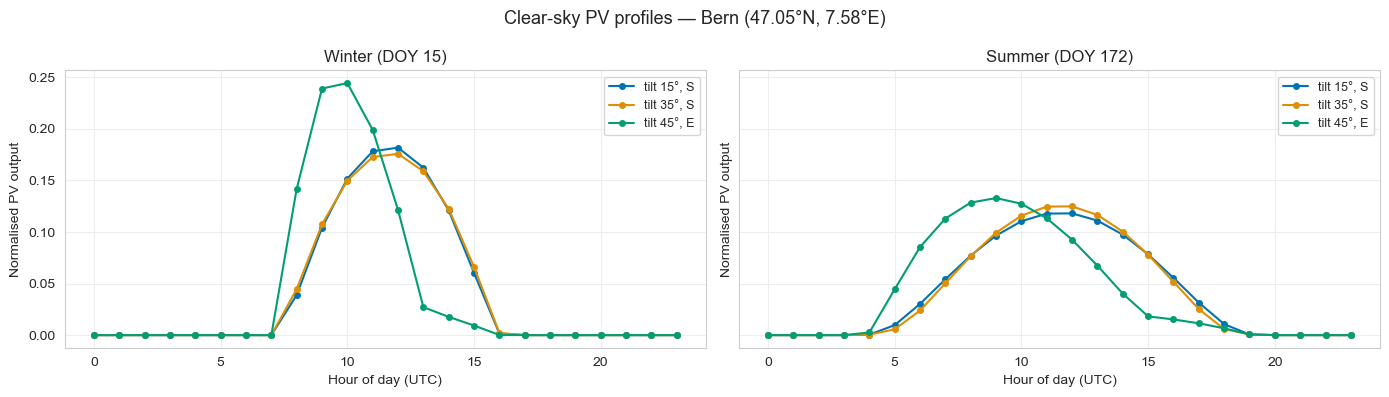

In [7]:
# --- Test compute_clearsky_profile for a single Swiss location ---
lat_test, lon_test = 47.05, 7.58  # Bern

fig, axes = plt.subplots(1, 2, figsize=(14, 4), sharey=True)
for ax, (doy, season) in zip(axes, [(15, "Winter (DOY 15)"), (172, "Summer (DOY 172)")]):
    for tilt_val, azimuth_val, lbl in [
        (15, 180, "tilt 15°, S"), (35, 180, "tilt 35°, S"), (45, 90, "tilt 45°, E"),
    ]:
        profile = compute_clearsky_profile(lat_test, lon_test, doy, tilt=tilt_val, azimuth=azimuth_val)
        ax.plot(range(24), profile, marker="o", ms=4, label=lbl)
    ax.set_xlabel("Hour of day (UTC)")
    ax.set_ylabel("Normalised PV output")
    ax.set_title(season)
    ax.legend(fontsize=9)

plt.suptitle(f"Clear-sky PV profiles — Bern ({lat_test}°N, {lon_test}°E)", fontsize=13)
plt.tight_layout()
plt.show()


Using variable: tilt_15_azimuth_E  (tilt=15°, azimuth=90°)
Grid point    : lat=47.350°N, lon=7.450°E


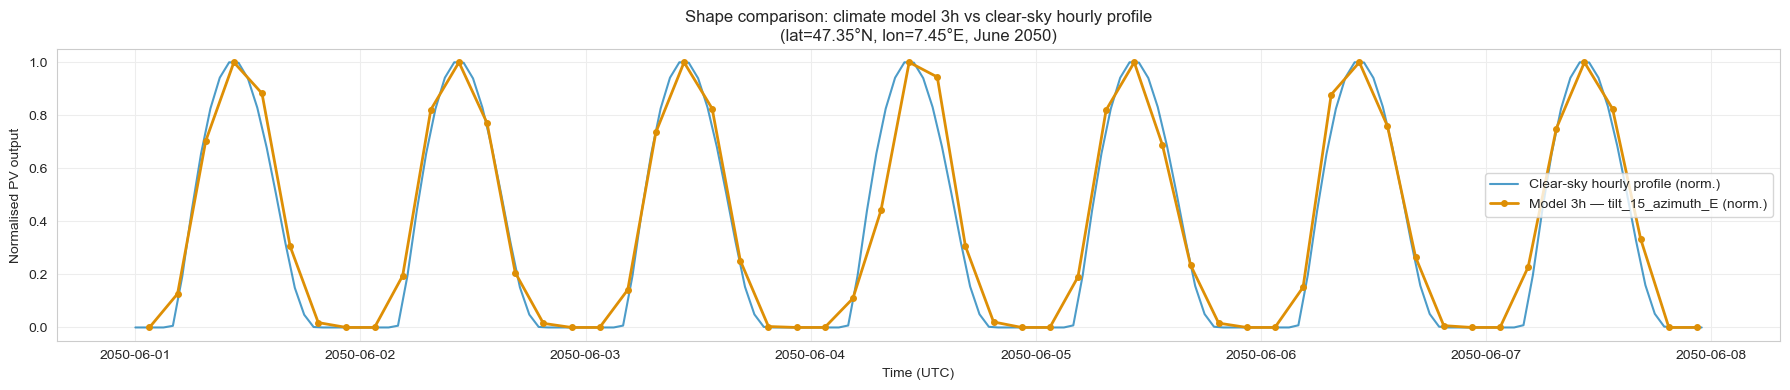

In [8]:
# --- Compare climate-model 3h PV output vs clear-sky hourly profile shape ---
# Pick the first data variable and extract its tilt / azimuth from the name
var_name    = list(ds_pv.data_vars)[0]
parts       = var_name.split("_")          # ["tilt", "35", "azimuth", "S"]
tilt_val    = int(parts[1])
azimuth_val = azimuths[parts[-1]]

print(f"Using variable: {var_name}  (tilt={tilt_val}°, azimuth={azimuth_val}°)")

# Select one grid point in central Switzerland for a summer week in 2050
pv_point = ds_pv[var_name].sel(time="2050-06").isel(lat=15, lon=15).compute()
lat_p, lon_p = float(pv_point.lat), float(pv_point.lon)
print(f"Grid point    : lat={lat_p:.3f}°N, lon={lon_p:.3f}°E")

# Build hourly clear-sky profile covering the first 7 days
doy0   = int(pd.Timestamp(str(pv_point.time.values[0])).dayofyear)
cs_7d  = np.concatenate([
    compute_clearsky_profile(lat_p, lon_p, doy0 + d, tilt=tilt_val, azimuth=azimuth_val)
    for d in range(7)
])
t0      = pd.Timestamp(str(pv_point.time.values[0])).floor("D")
hours   = pd.date_range(t0, periods=7 * 24, freq="h")

# 3-hourly model — first 7 days (56 steps)
pv_7d   = pv_point.isel(time=slice(0, 56))
times_3h = pd.DatetimeIndex(pv_7d.time.values)

# Normalise both by their respective daily peak for a shape comparison
def _norm_daily_peak(arr, n_per_day):
    n_days = len(arr) // n_per_day
    out = np.empty_like(arr, dtype=float)
    for d in range(n_days):
        sl  = slice(d * n_per_day, (d + 1) * n_per_day)
        mx  = arr[sl].max()
        out[sl] = arr[sl] / mx if mx > 0 else 0.0
    return out

norm_cs  = _norm_daily_peak(cs_7d, 24)
norm_pv  = _norm_daily_peak(pv_7d.values, 8)

fig, ax = plt.subplots(figsize=(18, 4))
ax.plot(hours, norm_cs, lw=1.5, alpha=0.7, label="Clear-sky hourly profile (norm.)")
ax.plot(times_3h, norm_pv, "o-", lw=2, ms=4, label=f"Model 3h — {var_name} (norm.)")
ax.set_xlabel("Time (UTC)")
ax.set_ylabel("Normalised PV output")
ax.set_title(
    f"Shape comparison: climate model 3h vs clear-sky hourly profile\n"
    f"(lat={lat_p:.2f}°N, lon={lon_p:.2f}°E, June 2050)"
)
ax.legend()
plt.tight_layout()
plt.show()


In [9]:
# --- Generate clear-sky profiles + disaggregate for a small 5×5 spatial subset ---
var_name    = list(ds_pv.data_vars)[0]
parts       = var_name.split("_")
tilt_val    = int(parts[1])
azimuth_val = azimuths[parts[-1]]

# 3-hourly PV for year 2050, 5×5 grid subset
pv_3h_sub  = ds_pv[var_name].sel(time="2050").isel(lat=slice(5, 10), lon=slice(5, 10))
lat_vals   = pv_3h_sub.lat.values
lon_vals   = pv_3h_sub.lon.values

print(f"Variable : {var_name}  (tilt={tilt_val}°, azimuth={azimuth_val}°)")
print(f"Grid     : {len(lat_vals)} lat × {len(lon_vals)} lon")
print(f"Steps    : {len(pv_3h_sub.time)} × 3 h  →  {len(pv_3h_sub.time) * 3} expected hourly rows\n")

# Dask-backed clear-sky profiles for every (lat, lon, day)
profiles_sub = generate_clearsky_profiles(
    lat_vals, lon_vals, tilt_val, azimuth_val,
    chunks={"lat": 5, "lon": 5, "day": 30},
)
print("Profiles (lazy):")
print(profiles_sub, "\n")

# Disaggregate: 3 h → 1 h  (still lazy at this point)
pv_hourly_sub = disaggregate_pv_to_hourly(pv_3h_sub, profiles_sub)
print("Hourly output (lazy):")
pv_hourly_sub


Variable : tilt_15_azimuth_E  (tilt=15°, azimuth=90°)
Grid     : 5 lat × 5 lon
Steps    : 2920 × 3 h  →  8760 expected hourly rows

Profiles (lazy):
<xarray.DataArray 'clearsky_pv_profile' (lat: 5, lon: 5, day: 366, hour: 24)> Size: 878kB
dask.array<transpose, shape=(5, 5, 366, 24), dtype=float32, chunksize=(5, 5, 30, 24), chunktype=numpy.ndarray>
Coordinates:
  * lat      (lat) float64 40B 46.35 46.45 46.55 46.65 46.75
  * lon      (lon) float64 40B 6.45 6.55 6.65 6.75 6.85
  * day      (day) int64 3kB 1 2 3 4 5 6 7 8 ... 359 360 361 362 363 364 365 366
  * hour     (hour) int64 192B 0 1 2 3 4 5 6 7 8 ... 15 16 17 18 19 20 21 22 23
Attributes:
    description:  Normalized clear-sky PV profile (sums to 1 per day per loca...
    tilt_deg:     15.0
    azimuth_deg:  90.0
    units:        fraction 

Hourly output (lazy):


<xarray.DataArray 'tilt_15_azimuth_E' (lat: 5, lon: 5, time: 8760)> Size: 2MB
dask.array<getitem, shape=(5, 5, 8760), dtype=float64, chunksize=(5, 5, 8760), chunktype=numpy.ndarray>
Coordinates:
  * lat      (lat) float64 40B 46.35 46.45 46.55 46.65 46.75
  * lon      (lon) float64 40B 6.45 6.55 6.65 6.75 6.85
    day      (time) int64 70kB 1 1 1 1 1 1 1 1 ... 365 365 365 365 365 365 365
    hour     (time) int64 70kB 0 1 2 3 4 5 6 7 8 ... 15 16 17 18 19 20 21 22 23
  * time     (time) datetime64[ns] 70kB 2050-01-01T00:30:00 ... 2050-12-31T23...
Attributes:
    description:  Hourly PV disaggregated from 3-hourly averages
    units:        
    method:       clear-sky profile weighting

In [10]:
# --- Energy-conservation check ---
# Each 3-h average represents 3 h of energy; the three disaggregated hourly
# values should sum to the same total.
energy_3h = (pv_3h_sub * 3).sum("time").compute()
energy_1h = pv_hourly_sub.sum("time").compute()

rel_err = (energy_1h - energy_3h) / energy_3h.where(energy_3h > 0) * 100

print(f"Energy conservation (relative error across all grid points):")
print(f"  max  : {float(rel_err.max()):.2e} %")
print(f"  mean : {float(rel_err.mean()):.2e} %")
print(f"  (≈0 means perfect conservation; small float errors are expected)")


Energy conservation (relative error across all grid points):
  max  : -8.49e-04 %
  mean : -4.62e-03 %
  (≈0 means perfect conservation; small float errors are expected)


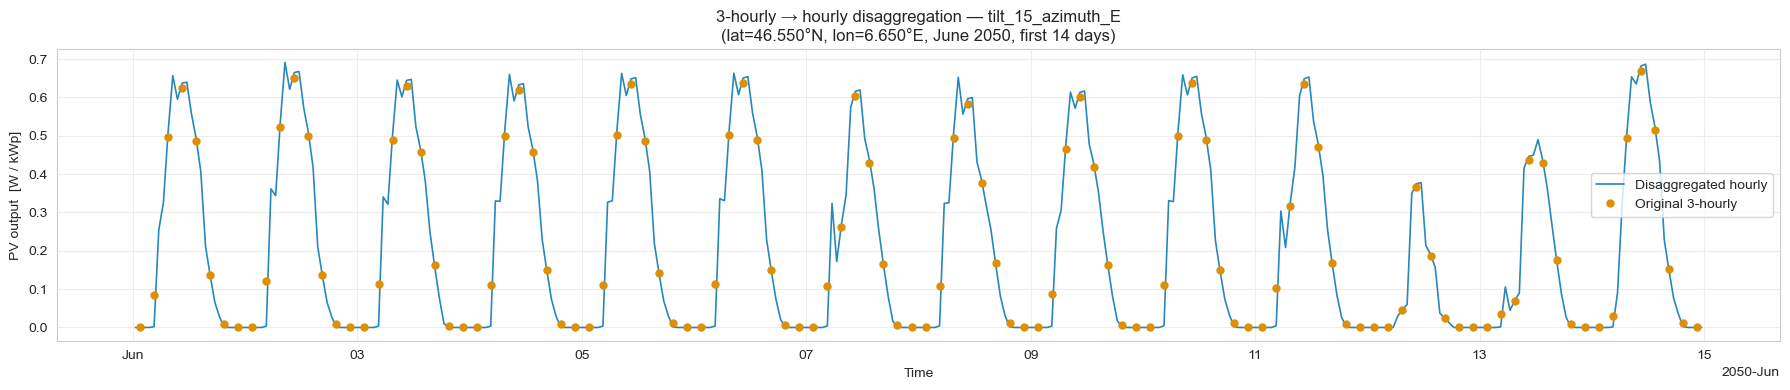

In [11]:
# --- Visualise 3-hourly vs disaggregated hourly for one grid point ---
# Select a two-week window in June 2050 at the centre of the subset
pv_3h_point  = pv_3h_sub.isel(lat=2, lon=2).sel(time="2050-06").compute()
pv_1h_point  = pv_hourly_sub.isel(lat=2, lon=2).sel(time="2050-06").compute()
lat_p, lon_p = float(pv_3h_point.lat), float(pv_3h_point.lon)

n_days = 14
fig, ax = plt.subplots(figsize=(18, 4))
pv_1h_point.isel(time=slice(0, n_days * 24)).plot(
    ax=ax, lw=1.2, alpha=0.85, label="Disaggregated hourly"
)
pv_3h_point.isel(time=slice(0, n_days * 8)).plot(
    ax=ax, marker="o", ms=5, lw=0, color="C1", label="Original 3-hourly", zorder=5
)
ax.set_title(
    f"3-hourly → hourly disaggregation — {var_name}\n"
    f"(lat={lat_p:.3f}°N, lon={lon_p:.3f}°E, June 2050, first {n_days} days)"
)
ax.set_xlabel("Time")
ax.set_ylabel("PV output  [W / kWp]")
ax.legend()
plt.tight_layout()
plt.show()


## Full Switzerland grid (all years)


In [ ]:
# --- Loop over every variable in the dataset ---
# For each tilt / azimuth combination, build profiles once and disaggregate
# the full time series.  Everything is lazy until the to_zarr() call.

from dask.diagnostics import ProgressBar

hourly_vars = {}

for vname in ds_pv:
    vparts    = vname.split("_")          # ["tilt", "35", "azimuth", "S"]
    v_tilt    = int(vparts[1])
    v_azimuth = azimuths[vparts[-1]]

    pv_3h_full = ds_pv[vname]
    lat_all    = pv_3h_full.lat.values
    lon_all    = pv_3h_full.lon.values

    print(f"{vname:30s}  —  grid {len(lat_all)} × {len(lon_all)}, "
          f"{len(pv_3h_full.time)} 3h steps  "
          f"({pv_3h_full.nbytes / 1e9:.2f} GB in memory)")

    profiles_full = generate_clearsky_profiles(
        lat_all, lon_all, v_tilt, v_azimuth,
        chunks={**spatial_chunks, "day": 30},
    )

    pv_hourly_full = disaggregate_pv_to_hourly(pv_3h_full, profiles_full)
    hourly_vars[vname] = pv_hourly_full

# Merge all variables into a single Dataset
ds_pv_hourly = xr.Dataset(hourly_vars)
print("\nFull hourly Dataset (lazy):")
print(ds_pv_hourly)


tilt_15_azimuth_E               —  grid 21 × 46, 318280 3h steps  (2.46 GB in memory)


tilt_15_azimuth_E               —  grid 21 × 46, 318280 3h steps  (2.46 GB in memory)


/home/yhaddad/.conda/envs/bias_correction_2024/lib/python3.11/site-packages/dask/utils.py:460: PerformanceWarning: Reshaping is producing a large chunk. To accept the large
chunk and silence this warning, set the option
    >>> with dask.config.set(**{'array.slicing.split_large_chunks': False}):
    ...     array.reshape(shape)

To avoid creating the large chunks, set the option
    >>> with dask.config.set(**{'array.slicing.split_large_chunks': True}):
    ...     array.reshape(shape)Explicitly passing ``limit`` to ``reshape`` will also silence this warning
    >>> array.reshape(shape, limit='128 MiB')
  return self.fn(key)


tilt_15_azimuth_E               —  grid 21 × 46, 318280 3h steps  (2.46 GB in memory)


/home/yhaddad/.conda/envs/bias_correction_2024/lib/python3.11/site-packages/dask/utils.py:460: PerformanceWarning: Reshaping is producing a large chunk. To accept the large
chunk and silence this warning, set the option
    >>> with dask.config.set(**{'array.slicing.split_large_chunks': False}):
    ...     array.reshape(shape)

To avoid creating the large chunks, set the option
    >>> with dask.config.set(**{'array.slicing.split_large_chunks': True}):
    ...     array.reshape(shape)Explicitly passing ``limit`` to ``reshape`` will also silence this warning
    >>> array.reshape(shape, limit='128 MiB')
  return self.fn(key)


...

tilt_25_azimuth_SE              —  grid 21 × 46, 318280 3h steps  (2.46 GB in memory)


Exception ignored in: <bound method IPythonKernel._clean_thread_parent_frames of <ipykernel.ipkernel.IPythonKernel object at 0x7faf366ac350>>
Traceback (most recent call last):
  File "/home/yhaddad/.conda/envs/bias_correction_2024/lib/python3.11/site-packages/ipykernel/ipkernel.py", line 775, in _clean_thread_parent_frames
    def _clean_thread_parent_frames(

KeyboardInterrupt: 
/home/yhaddad/.conda/envs/bias_correction_2024/lib/python3.11/site-packages/dask/utils.py:460: PerformanceWarning: Reshaping is producing a large chunk. To accept the large
chunk and silence this warning, set the option
    >>> with dask.config.set(**{'array.slicing.split_large_chunks': False}):
    ...     array.reshape(shape)

To avoid creating the large chunks, set the option
    >>> with dask.config.set(**{'array.slicing.split_large_chunks': True}):
    ...     array.reshape(shape)Explicitly passing ``limit`` to ``reshape`` will also silence this warning
    >>> array.reshape(shape, limit='128 MiB')
  ret

tilt_25_azimuth_SW              —  grid 21 × 46, 318280 3h steps  (2.46 GB in memory)


/home/yhaddad/.conda/envs/bias_correction_2024/lib/python3.11/site-packages/dask/utils.py:460: PerformanceWarning: Reshaping is producing a large chunk. To accept the large
chunk and silence this warning, set the option
    >>> with dask.config.set(**{'array.slicing.split_large_chunks': False}):
    ...     array.reshape(shape)

To avoid creating the large chunks, set the option
    >>> with dask.config.set(**{'array.slicing.split_large_chunks': True}):
    ...     array.reshape(shape)Explicitly passing ``limit`` to ``reshape`` will also silence this warning
    >>> array.reshape(shape, limit='128 MiB')
  return self.fn(key)


tilt_25_azimuth_W               —  grid 21 × 46, 318280 3h steps  (2.46 GB in memory)


In [ ]:
# --- Write to Zarr — triggers Dask computation ---
# Uncomment when ready to run on the full dataset.
# For a laptop, limit to a single year or a spatial subset first.

# output_path_hourly = (
#     path_energy_ch / "pv"
#     / f"{climate_model_chain}_{climate_scenario}"
#     / f"pv_hourly_{climate_model_chain}_{climate_scenario}.zarr"
# )
# with ProgressBar():
#     ds_pv_hourly.to_zarr(output_path_hourly, mode="w")
# print(f"Saved to {output_path_hourly}")


## Method comparison: Clear-sky profiles vs Radiation interpolation

Two disaggregation strategies are available:

| | **Clear-sky profiles** (this notebook) | **Radiation interpolation** (`disaggregate_pv.py`) |
|---|---|---|
| **Weights source** | pvlib Ineichen model for each (lat, lon, DOY, tilt, azimuth) | Actual bias-corrected rsds — cubic-spline interpolated to 1 h |
| **Inputs needed** | `pv_3h` + geometry params | `pv_3h` + `rsds_3h` |
| **Captures clouds?** | ❌ — uses clear-sky envelope | ✅ — follows real/modelled cloudiness |
| **Handles polar winter / no-data?** | ✅ — zero profile when sun below horizon | ✅ — masked via radiation threshold |
| **Energy conservation** | Exact by construction | Exact after scaling correction pass |

Below we run both on the same 3-hourly CH PV subset and compare the results.

In [12]:
# --- Load bias-corrected rsds for the same model/scenario ---
# rsds lives in the same cordex_processed tree that compute_pv.py reads from.
path_rsds = (
    path_data_processed
    / "cordex_processed"
    / f"{climate_model_chain}_{climate_scenario}"
    / "bias_corrected"
    / "3hr"
    / "rsds.zarr"
)
ds_rsds = xr.open_zarr(path_rsds, chunks="auto")

# Select the exact same spatial subset and year as pv_3h_sub (cell above)
rsds_sub = (
    ds_rsds["rsds"]
    .sel(time="2050")
    .sel(lat=pv_3h_sub.lat.values, lon=pv_3h_sub.lon.values)
)

# Verify time alignment; select to pv_3h_sub.time if coordinates differ
print("pv_3h_sub time[:3] :", pv_3h_sub.time.values[:3])
print("rsds_sub  time[:3] :", rsds_sub.time.values[:3])

rsds_sub = rsds_sub.sel(time=pv_3h_sub.time, method="nearest", tolerance="30min")
print("\nAligned rsds_sub:", rsds_sub)


pv_3h_sub time[:3] : ['2050-01-01T01:30:00.000000000' '2050-01-01T04:30:00.000000000'
 '2050-01-01T07:30:00.000000000']
rsds_sub  time[:3] : ['2050-01-01T01:30:00.000000000' '2050-01-01T04:30:00.000000000'
 '2050-01-01T07:30:00.000000000']

Aligned rsds_sub: <xarray.DataArray 'rsds' (time: 2920, lat: 5, lon: 5)> Size: 292kB
dask.array<getitem, shape=(2920, 5, 5), dtype=float32, chunksize=(2920, 5, 5), chunktype=numpy.ndarray>
Coordinates:
  * lat      (lat) float64 40B 46.35 46.45 46.55 46.65 46.75
  * lon      (lon) float64 40B 6.45 6.55 6.65 6.75 6.85
  * time     (time) datetime64[ns] 23kB 2050-01-01T01:30:00 ... 2050-12-31T22...
Attributes:
    bias_adjustment:     EmpiricalQuantileMapping(group=Grouper(name='time.da...
    cell_methods:        time: mean
    history:             [2025-09-03 06:01:27] : Bias-adjusted with Empirical...
    interval_operation:  450 s
    interval_write:      3 h
    long_name:           Surface Downwelling Shortwave Radiation
    online_operation:   

In [15]:
def disaggregate_pv_radiation_xr(pv_3h, rsds_3h, threshold=5.0):
    """Radiation-interpolation disaggregation (mirrors disaggregate_pv.py).

    For each 3-hourly step at timestamp t the value is distributed over the
    three adjacent hours [t-1h, t, t+1h] proportionally to bias-corrected
    rsds cubic-interpolated to those hours.  Uses the same ×3 energy-
    conservation scaling as :func:`disaggregate_pv_to_hourly`.

    Parameters
    ----------
    pv_3h : xr.DataArray, dims (time, lat, lon)
        3-hourly PV averages.
    rsds_3h : xr.DataArray, dims (time, lat, lon)
        Bias-corrected 3-hourly surface downwelling shortwave radiation [W/m²].
        Must share the same time coordinate as pv_3h.
    threshold : float
        rsds values below this [W/m²] are treated as night → output set to 0.
    """
    one_hour_ns = np.timedelta64(1, "h").astype("timedelta64[ns]")
    offsets = np.array([-1, 0, 1])

    times_3h    = pv_3h.time.values                                      # (N,)
    new_times_2d = times_3h[:, None] + offsets[None, :] * one_hour_ns   # (N, 3)
    target_times = np.sort(np.unique(new_times_2d.ravel()))              # unique hourly times

    # 1. Cubic-spline interpolation of rsds to target hourly timestamps
    rsds_1h = rsds_3h.interp(
        time=target_times,
        method="cubic",
        kwargs={"fill_value": 0.0},
    ).clip(min=0.0)

    # 2. For each 3h step collect rsds at t-1h, t, t+1h → (N, 3, lat, lon)
    # Reset time coordinate to times_3h so all three slices share the same
    # index and can be concatenated without alignment errors in .where().
    rsds_blocks = xr.concat(
        [
            rsds_1h.sel(time=times_3h + off * one_hour_ns)
                   .assign_coords(time=times_3h)
            for off in offsets
        ],
        dim=xr.DataArray(offsets, dims="offset"),
    ).transpose("time", "offset", "lat", "lon")

    # 3. Normalise within each 3h block (weights sum to 1 per block)
    block_sum = rsds_blocks.sum("offset").where(lambda x: x > 0, other=1.0)
    weights   = rsds_blocks / block_sum

    # 4. Distribute and scale ×3 (same energy convention as disaggregate_pv_to_hourly)
    pv_expanded = (
        pv_3h
        .expand_dims(offset=offsets)
        .transpose("time", "offset", "lat", "lon")
    )
    pv_hourly_2d = pv_expanded * weights * 3

    # 5. Night mask
    pv_hourly_2d = pv_hourly_2d.where(rsds_blocks >= threshold, 0.0)

    # 6. Flatten to 1-D time axis (same pattern as disaggregate_pv_to_hourly)
    hourly_ts = new_times_2d.ravel()
    pv_hourly = (
        pv_hourly_2d
        .stack(new_time=("time", "offset"))
        .drop_vars(["new_time", "time", "offset"])
        .assign_coords(new_time=hourly_ts)
        .rename(new_time="time")
        .sortby("time")
    )
    pv_hourly.attrs.update({
        "description": "Hourly PV disaggregated from 3-hourly averages",
        "units": pv_3h.attrs.get("units", ""),
        "method": "radiation interpolation (cubic spline)",
    })
    return pv_hourly

print("disaggregate_pv_radiation_xr defined")


disaggregate_pv_radiation_xr defined


In [16]:
# --- Run both methods on the 5×5 subset for June 2050 ---
# (pv_3h_sub and pv_hourly_sub are from the earlier subset test cells)

pv_3h_june    = pv_3h_sub.sel(time="2050-06").load()
# .chunk({"time": -1, "lat": 5, "lon": 5})
rsds_3h_june  = rsds_sub.sel(time="2050-06").load()
# .chunk({"time": -1, "lat": 5, "lon": 5})

# Method 1: clear-sky profiles (already computed for full 2050 above)
pv_1h_cs  = pv_hourly_sub.sel(time="2050-06").compute()

In [17]:
# Method 2: radiation interpolation
print("Running radiation disaggregation …")
pv_1h_rad = disaggregate_pv_radiation_xr(pv_3h_june, rsds_3h_june).compute()

print(f"\nClear-sky : shape={pv_1h_cs.shape},  "
      f"time [{pv_1h_cs.time.values[0]}  …  {pv_1h_cs.time.values[-1]}]")
print(f"Radiation : shape={pv_1h_rad.shape},  "
      f"time [{pv_1h_rad.time.values[0]}  …  {pv_1h_rad.time.values[-1]}]")


Running radiation disaggregation …

Clear-sky : shape=(5, 5, 720),  time [2050-06-01T00:30:00.000000000  …  2050-06-30T23:30:00.000000000]
Radiation : shape=(5, 5, 720),  time [2050-06-01T00:30:00.000000000  …  2050-06-30T23:30:00.000000000]


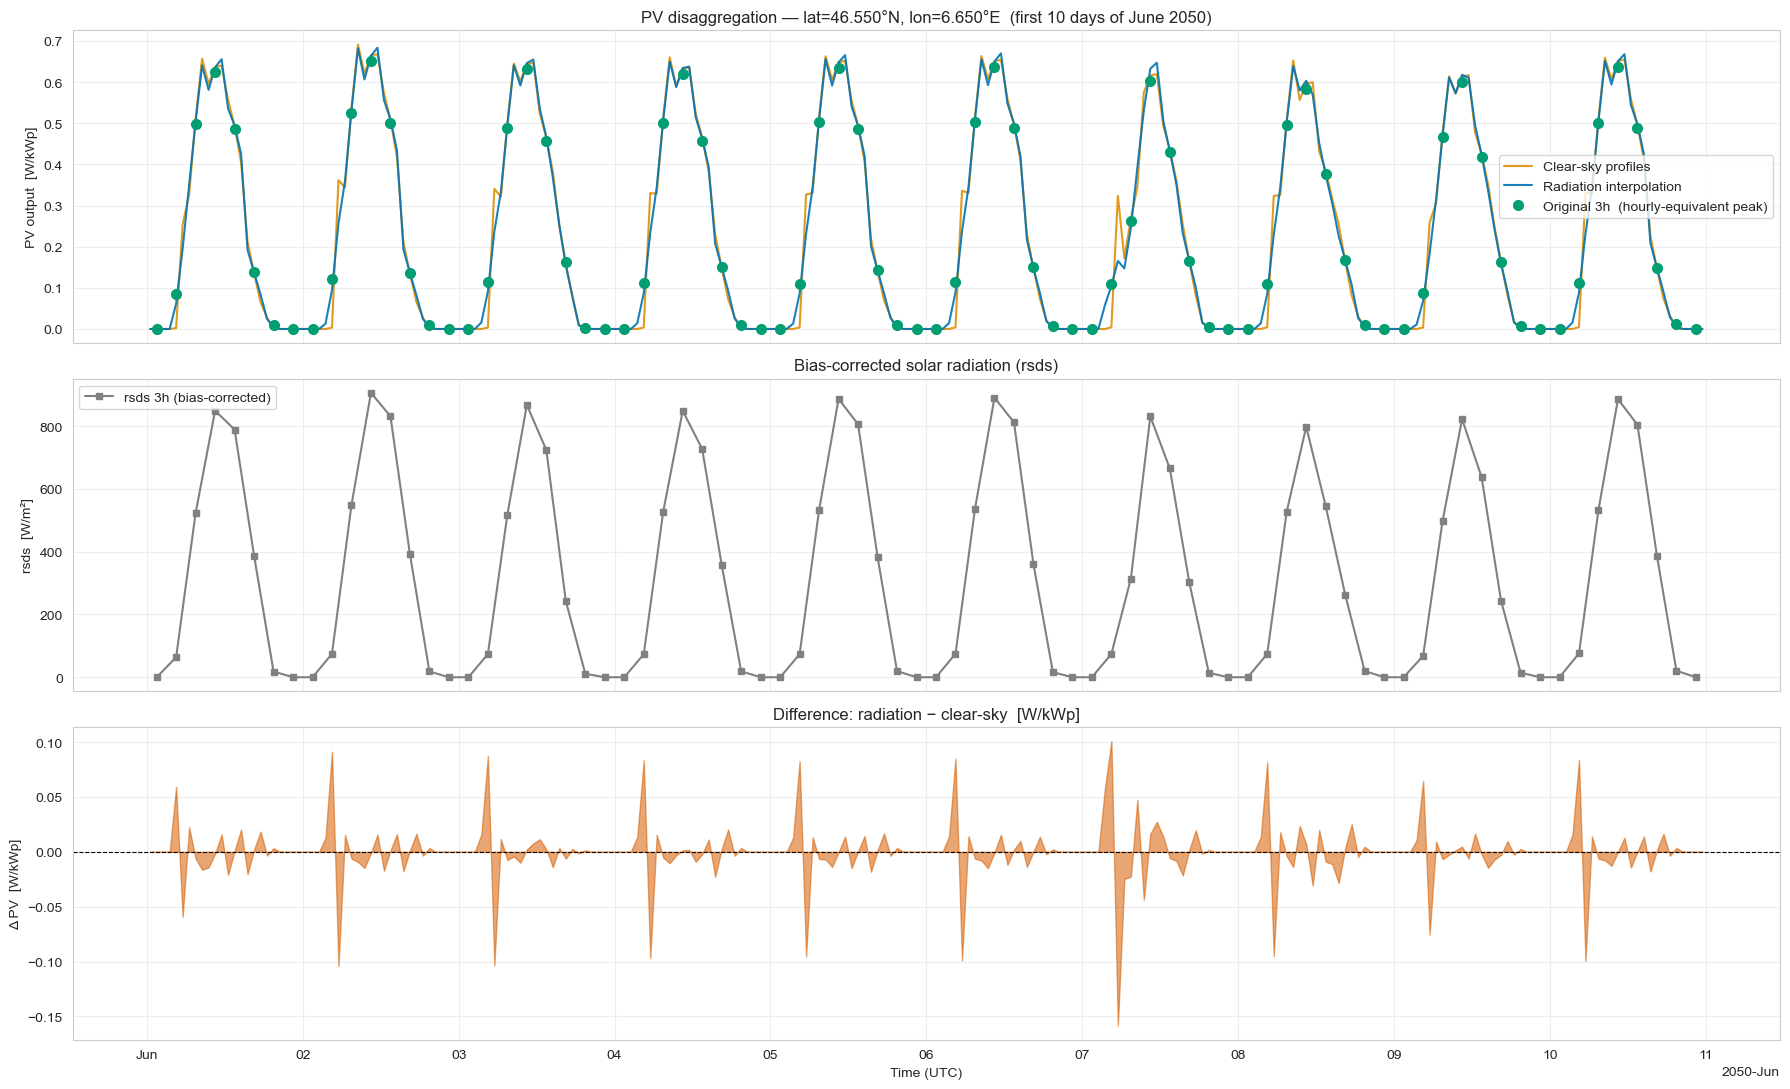

In [20]:
# --- Time-series comparison at one grid point ---
i_lat, i_lon = 2, 2
lat_p = float(pv_3h_june.lat.isel(lat=i_lat))
lon_p = float(pv_3h_june.lon.isel(lon=i_lon))
n_days = 10

t0 = pd.Timestamp(str(pv_3h_june.time.values[0])).floor("D")
t1 = t0 + pd.Timedelta(days=n_days)

pv_3h_pt  = pv_3h_june.isel(lat=i_lat, lon=i_lon).sel(time=slice(t0, t1)).compute()
pv_cs_pt  = pv_1h_cs.isel(lat=i_lat, lon=i_lon).sel(time=slice(t0, t1))
pv_rad_pt = pv_1h_rad.isel(lat=i_lat, lon=i_lon).sel(time=slice(t0, t1))
rsds_pt   = rsds_3h_june.isel(lat=i_lat, lon=i_lon).sel(time=slice(t0, t1)).compute()

fig, axes = plt.subplots(3, 1, figsize=(18, 11), sharex=True)

# --- PV panel ---
ax = axes[0]
pv_cs_pt.plot(ax=ax, lw=1.5, color="C1", alpha=0.9, label="Clear-sky profiles")
pv_rad_pt.plot(ax=ax, lw=1.5, color="C0", alpha=0.9, label="Radiation interpolation")
(pv_3h_pt).plot(
    ax=ax, marker="o", ms=7, lw=0, color="C2",
    label="Original 3h  (hourly-equivalent peak)", zorder=5,
)
ax.set_title(
    f"PV disaggregation — lat={lat_p:.3f}°N, lon={lon_p:.3f}°E  "
    f"(first {n_days} days of June 2050)",
    fontsize=12,
)
ax.legend(fontsize=10)
ax.set_xlabel("")
ax.set_ylabel("PV output  [W/kWp]")

# --- Radiation panel ---
ax2 = axes[1]
rsds_pt.plot(ax=ax2, marker="s", ms=4, lw=1.5, color="grey",
             label="rsds 3h (bias-corrected)")
ax2.set_title("Bias-corrected solar radiation (rsds)")
ax2.legend(fontsize=10)
ax2.set_xlabel("")
ax2.set_ylabel("rsds  [W/m²]")

# --- Difference panel ---
# Align on a common time index before differencing
common_time = np.intersect1d(pv_rad_pt.time.values, pv_cs_pt.time.values)
diff = (
    pv_rad_pt.sel(time=common_time).values
    - pv_cs_pt.sel(time=common_time).values
)
ax3 = axes[2]
ax3.fill_between(pv_cs_pt.sel(time=common_time).time.values, diff,
                 alpha=0.55, color="C3")
ax3.axhline(0, color="k", lw=0.8, ls="--")
ax3.set_title("Difference: radiation − clear-sky  [W/kWp]")
ax3.set_xlabel("Time (UTC)")
ax3.set_ylabel("Δ PV  [W/kWp]")

plt.tight_layout()
plt.show()


Energy conservation — relative error over 5×5 grid, June 2050:
  Clear-sky profiles  —  max: +7.743e-07%   mean: -2.482e-08%
  Radiation interp.   —  max: +1.120e-13%   mean: -2.584e-03%


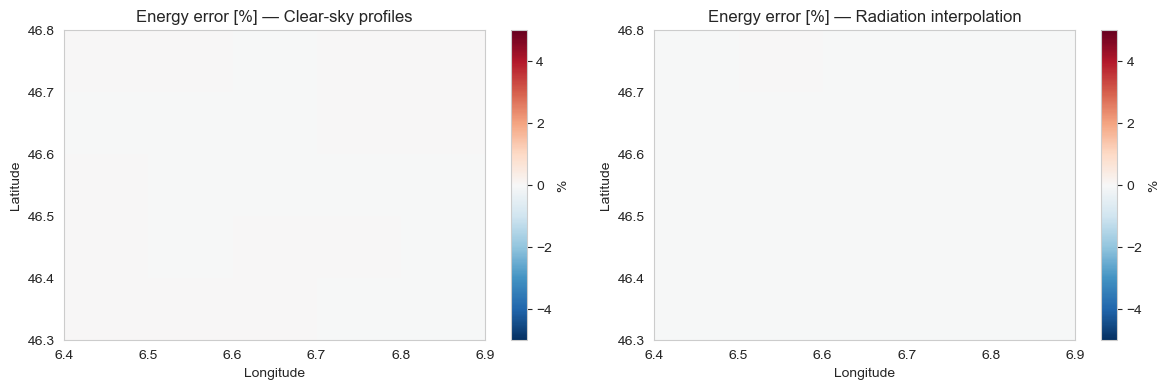

In [19]:
# --- Energy conservation check: both methods vs original 3h ---
# The clear-sky method guarantees sum(3 hourly outputs) = pv_3h * 3.
# The radiation method should too, EXCEPT where the night mask zeroes out
# a step that had pv_3h > 0 (edge case at dawn/dusk).

energy_3h  = (pv_3h_june * 3).sum("time").compute()
energy_cs  = pv_1h_cs.sum("time").compute()
energy_rad = pv_1h_rad.sum("time").compute()

# Common spatial extent (in case of minor coordinate drift)
energy_cs  = energy_cs.sel(lat=energy_3h.lat, lon=energy_3h.lon, method="nearest")
energy_rad = energy_rad.sel(lat=energy_3h.lat, lon=energy_3h.lon, method="nearest")

rel_err_cs  = (energy_cs  - energy_3h) / energy_3h.where(energy_3h > 0) * 100
rel_err_rad = (energy_rad - energy_3h) / energy_3h.where(energy_3h > 0) * 100

print("Energy conservation — relative error over 5×5 grid, June 2050:")
print(f"  Clear-sky profiles  —  max: {float(rel_err_cs.max()):+.3e}%   "
      f"mean: {float(rel_err_cs.mean()):+.3e}%")
print(f"  Radiation interp.   —  max: {float(rel_err_rad.max()):+.3e}%   "
      f"mean: {float(rel_err_rad.mean()):+.3e}%")

# Visualise spatial pattern of the error for the radiation method
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, err, title in zip(
    axes,
    [rel_err_cs, rel_err_rad],
    ["Clear-sky profiles", "Radiation interpolation"],
):
    im = ax.pcolormesh(err.lon, err.lat, err, cmap="RdBu_r", vmin=-5, vmax=5)
    ax.set_title(f"Energy error [%] — {title}")
    ax.set_xlabel("Longitude")
    ax.set_ylabel("Latitude")
    plt.colorbar(im, ax=ax, label="%")
plt.tight_layout()
plt.show()


Days with same peak hour : 15 / 30
Max shift                : 3 h


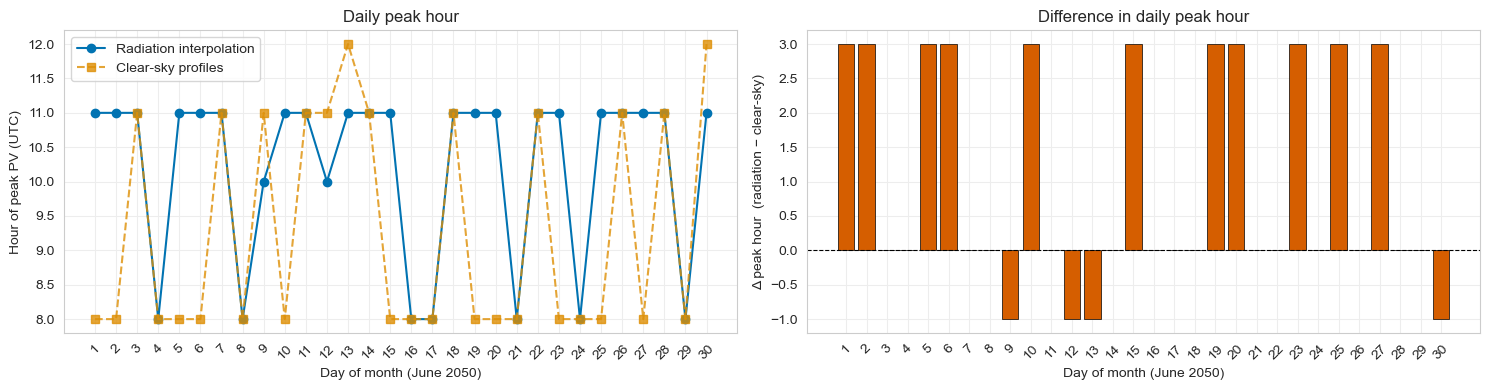

In [21]:
# --- Daily peak-hour comparison at the central grid point ---
# For each day in June 2050, find the hour (UTC) at which PV peaks.

def daily_peak_hour_series(pv_1h, i_lat, i_lon):
    """Return a pandas Series of peak hour-of-day for each calendar day."""
    s = pv_1h.isel(lat=i_lat, lon=i_lon).to_series()
    return s.groupby(s.index.date).apply(
        lambda x: x.idxmax().hour if x.max() > 0 else np.nan
    )

peak_cs  = daily_peak_hour_series(pv_1h_cs,  i_lat, i_lon)
peak_rad = daily_peak_hour_series(pv_1h_rad, i_lat, i_lon)

# Align on common days
common_days = peak_cs.index.intersection(peak_rad.index)
peak_cs  = peak_cs.loc[common_days]
peak_rad = peak_rad.loc[common_days]

fig, axes = plt.subplots(1, 2, figsize=(15, 4))

ax = axes[0]
ax.plot(range(len(common_days)), peak_rad.values, "o-", color="C0",
        ms=6, label="Radiation interpolation")
ax.plot(range(len(common_days)), peak_cs.values, "s--", color="C1",
        ms=6, alpha=0.8, label="Clear-sky profiles")
ax.set_xlabel("Day of month (June 2050)")
ax.set_ylabel("Hour of peak PV (UTC)")
ax.set_title("Daily peak hour")
ax.legend(fontsize=10)
ax.set_xticks(range(len(common_days)))
ax.set_xticklabels([str(d.day) for d in common_days], rotation=45)

ax2 = axes[1]
diff_peak = peak_rad.values.astype(float) - peak_cs.values.astype(float)
colors = ["C3" if d != 0 else "C7" for d in diff_peak]
ax2.bar(range(len(common_days)), diff_peak, color=colors, edgecolor="k", lw=0.5)
ax2.axhline(0, color="k", lw=0.8, ls="--")
ax2.set_xlabel("Day of month (June 2050)")
ax2.set_ylabel("Δ peak hour  (radiation − clear-sky)")
ax2.set_title("Difference in daily peak hour")
ax2.set_xticks(range(len(common_days)))
ax2.set_xticklabels([str(d.day) for d in common_days], rotation=45)
non_nan = ~np.isnan(diff_peak)
print(f"Days with same peak hour : {(diff_peak[non_nan] == 0).sum()} / {non_nan.sum()}")
print(f"Max shift                : {int(np.nanmax(np.abs(diff_peak)))} h")

plt.tight_layout()
plt.show()


## Method 3: Catmull-Rom cubic interpolation (Dask-compatible)

`disaggregate_pv_radiation_xr` uses `xr.interp(method="cubic")` which internally
calls `scipy.interpolate.CubicSpline` — a **global** spline that must materialise
the entire time axis before fitting. This prevents Dask from parallelising over
time chunks.

**Catmull-Rom** replaces the global spline with a **local 4-point** scheme.
At each 3-hourly knot $P_0$ the interpolated values at $t_0 \pm 1\text{h}$ are:

$$
P(t_0 - 1\text{h}) = -\tfrac{1}{27}P_{-2} + \tfrac{1}{3}P_{-1} + \tfrac{7}{9}P_0 - \tfrac{2}{27}P_{+1}
$$

$$
P(t_0 + 1\text{h}) = -\tfrac{2}{27}P_{-1} + \tfrac{7}{9}P_0 + \tfrac{1}{3}P_{+1} - \tfrac{1}{27}P_{+2}
$$

These are the standard uniform Catmull-Rom formula evaluated at $u = 2/3$ and
$u = 1/3$ within adjacent segments. Only `.shift(time=±1)` / `.shift(time=±2)` plus
elementwise operations are needed — Dask needs just a 2-step overlap, which it
handles natively.

In [22]:
def _catmull_rom_offsets(da):
    """Estimate rsds at t−1h, t, t+1h for each 3-hourly timestep using
    local Catmull-Rom cubic interpolation.

    Coefficients derived from the uniform Catmull-Rom formula evaluated at
    u=2/3 (for t−1h within segment [P₋₁, P₀]) and u=1/3 (for t+1h within
    segment [P₀, P₊₁]):

        t₀ − 1h :  −1/27 · P₋₂ + 1/3 · P₋₁ + 7/9 · P₀ − 2/27 · P₊₁
        t₀      :   P₀
        t₀ + 1h :  −2/27 · P₋₁ + 7/9 · P₀  + 1/3 · P₊₁ − 1/27 · P₊₂

    Only `.shift()` + elementwise ops → Dask-compatible (no global spline fit).

    Parameters
    ----------
    da : xr.DataArray with dim 'time' (and any spatial dims)
        3-hourly values.

    Returns
    -------
    xr.DataArray with dims (time, offset, ...)
        where offset ∈ [-1, 0, 1] hours.
    """
    Pm2 = da.shift(time=2)   # P₋₂ : 2 steps (6 h) earlier
    Pm1 = da.shift(time=1)   # P₋₁ : 1 step  (3 h) earlier
    P0  = da                  # P₀  : current knot
    Pp1 = da.shift(time=-1)  # P₊₁ : 1 step  (3 h) ahead
    Pp2 = da.shift(time=-2)  # P₊₂ : 2 steps (6 h) ahead

    val_minus1 = -(1/27)*Pm2 + (1/3)*Pm1 + (7/9)*P0  - (2/27)*Pp1
    val_plus1  = -(2/27)*Pm1 + (7/9)*P0  + (1/3)*Pp1 - (1/27)*Pp2

    offsets = np.array([-1, 0, 1])
    result = xr.concat(
        [val_minus1, P0, val_plus1],
        dim=xr.DataArray(offsets, dims="offset"),
    ).clip(min=0.0)

    # Ensure (time, offset, ...) ordering
    spatial_dims = [d for d in da.dims if d != "time"]
    return result.transpose("time", "offset", *spatial_dims)


def disaggregate_pv_catmullrom(pv_3h, rsds_3h, threshold=5.0):
    """Radiation-weighted PV disaggregation using Catmull-Rom interpolation.

    Drop-in replacement for ``disaggregate_pv_radiation_xr`` that avoids
    the global scipy cubic spline — only `.shift()` and elementwise
    operations are used, making this fully Dask-compatible.

    Parameters
    ----------
    pv_3h     : xr.DataArray (time, lat, lon)
    rsds_3h   : xr.DataArray (time, lat, lon), same time axis as pv_3h
    threshold : float  [W/m²] — below this rsds the output is set to zero

    Returns
    -------
    xr.DataArray (time_hourly, lat, lon)
    """
    one_hour_ns = np.timedelta64(1, "h").astype("timedelta64[ns]")
    offsets     = np.array([-1, 0, 1])
    times_3h    = pv_3h.time.values

    # 1. Catmull-Rom rsds estimates at t−1h, t, t+1h  →  (time, 3, lat, lon)
    rsds_blocks = _catmull_rom_offsets(rsds_3h)

    # 2. Radiation weights (sum to 1 per 3h block)
    block_sum = rsds_blocks.sum("offset").where(lambda x: x > 0, other=1.0)
    weights   = rsds_blocks / block_sum

    # 3. Distribute PV and scale ×3 (energy conservation)
    spatial_dims = [d for d in pv_3h.dims if d != "time"]
    pv_expanded  = pv_3h.expand_dims(offset=offsets).transpose(
        "time", "offset", *spatial_dims
    )
    pv_hourly_2d = pv_expanded * weights * 3

    # 4. Night mask
    pv_hourly_2d = pv_hourly_2d.where(rsds_blocks >= threshold, 0.0)

    # 5. Flatten (time, offset) → 1-D hourly time axis
    new_times_2d = times_3h[:, None] + offsets[None, :] * one_hour_ns
    hourly_ts    = new_times_2d.ravel()

    pv_hourly = (
        pv_hourly_2d
        .stack(new_time=("time", "offset"))
        .drop_vars(["new_time", "time", "offset"])
        .assign_coords(new_time=hourly_ts)
        .rename(new_time="time")
        .sortby("time")
    )
    pv_hourly.attrs.update({
        "description": "Hourly PV disaggregated from 3-hourly averages",
        "units"      : pv_3h.attrs.get("units", ""),
        "method"     : "radiation interpolation (Catmull-Rom)",
    })
    return pv_hourly


print("_catmull_rom_offsets and disaggregate_pv_catmullrom defined")


_catmull_rom_offsets and disaggregate_pv_catmullrom defined


In [23]:
# --- Run Catmull-Rom on June 2050 5×5 subset ---
print("Running Catmull-Rom disaggregation …")
pv_1h_cr = disaggregate_pv_catmullrom(pv_3h_june, rsds_3h_june).compute()

print(f"\nClear-sky   : shape={pv_1h_cs.shape}, "
      f"time [{pv_1h_cs.time.values[0]} … {pv_1h_cs.time.values[-1]}]")
print(f"Radiation   : shape={pv_1h_rad.shape}, "
      f"time [{pv_1h_rad.time.values[0]} … {pv_1h_rad.time.values[-1]}]")
print(f"Catmull-Rom : shape={pv_1h_cr.shape}, "
      f"time [{pv_1h_cr.time.values[0]} … {pv_1h_cr.time.values[-1]}]")


Running Catmull-Rom disaggregation …

Clear-sky   : shape=(5, 5, 720), time [2050-06-01T00:30:00.000000000 … 2050-06-30T23:30:00.000000000]
Radiation   : shape=(5, 5, 720), time [2050-06-01T00:30:00.000000000 … 2050-06-30T23:30:00.000000000]
Catmull-Rom : shape=(5, 5, 720), time [2050-06-01T00:30:00.000000000 … 2050-06-30T23:30:00.000000000]


Residuals at ±1h points — RMSE: nan W/m²    max|err|: nan W/m²


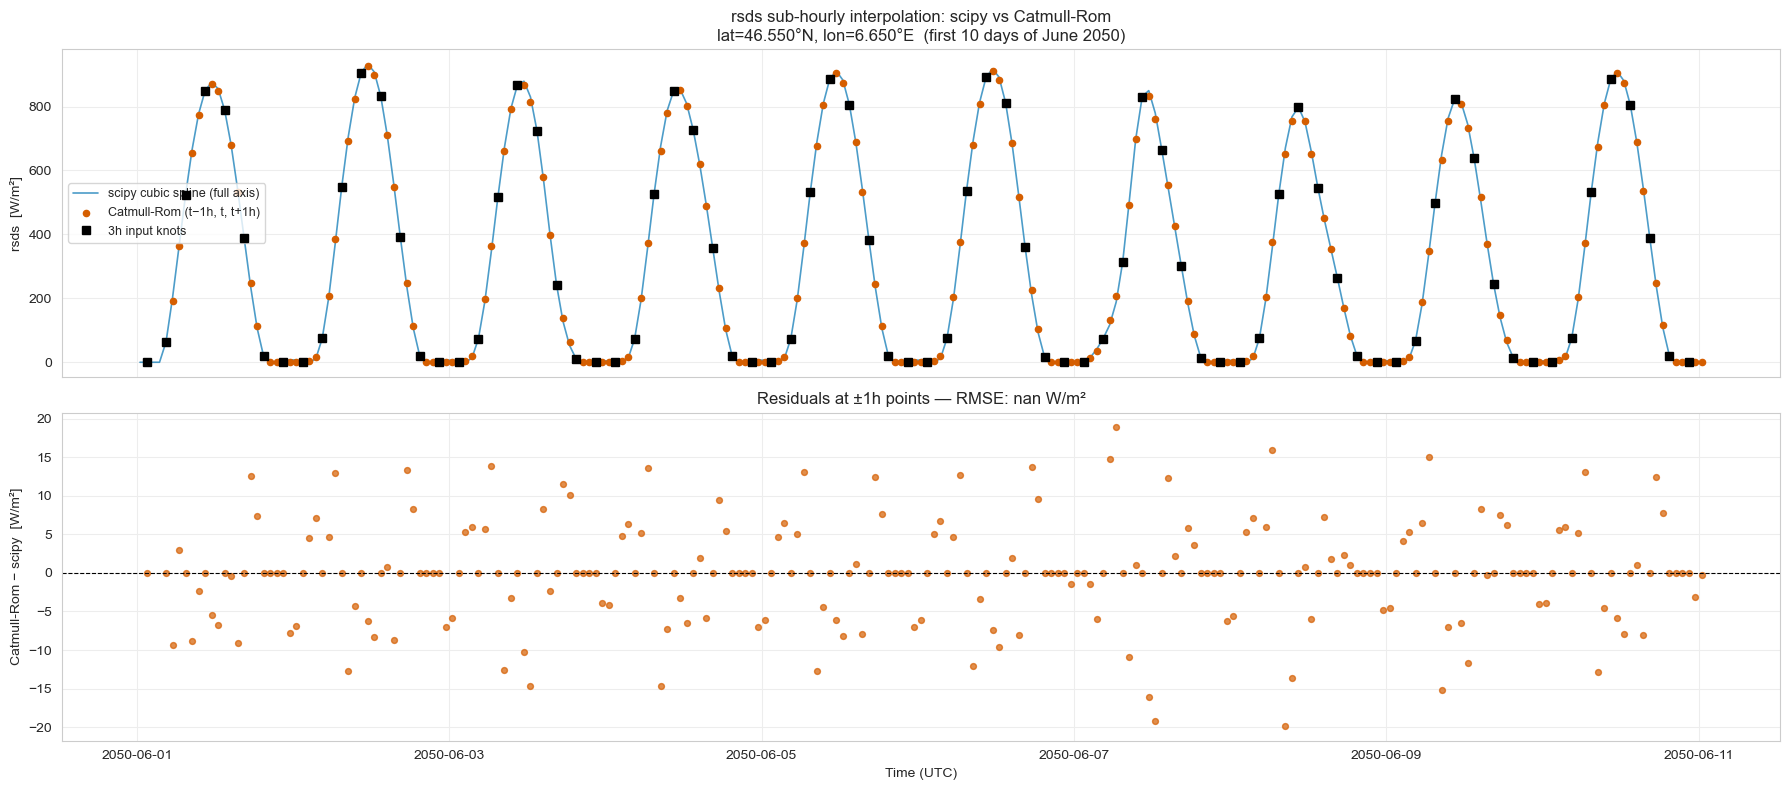

In [24]:
# --- rsds interpolation quality: scipy cubic spline vs Catmull-Rom ---
# Compare sub-hourly rsds estimates at t±1h for one grid point.

one_hour_ns = np.timedelta64(1, "h").astype("timedelta64[ns]")
offsets_arr = np.array([-1, 0, 1])
times_3h_arr = rsds_3h_june.time.values

target_times = np.sort(np.unique(
    (times_3h_arr[:, None] + offsets_arr[None, :] * one_hour_ns).ravel()
))

# scipy: fit cubic spline over the 3h grid, sample at hourly targets
rsds_1h_scipy = (
    rsds_3h_june.isel(lat=i_lat, lon=i_lon)
    .interp(time=target_times, method="cubic", kwargs={"fill_value": 0.0})
    .clip(min=0.0)
    .compute()
)

# Catmull-Rom: local 4-point estimate at t-1h, t, t+1h
rsds_cr_blk = _catmull_rom_offsets(rsds_3h_june.isel(lat=i_lat, lon=i_lon)).compute()
rsds_cr_times = (times_3h_arr[:, None] + offsets_arr[None, :] * one_hour_ns).ravel()
rsds_cr_vals  = rsds_cr_blk.values.ravel()

n_plot  = 10 * 8  # first 10 days
t_cut   = times_3h_arr[n_plot - 1] + 2 * one_hour_ns
mask_sp = rsds_1h_scipy.time.values <= t_cut
mask_cr = rsds_cr_times <= t_cut
mask_3h = times_3h_arr <= t_cut

rsds_3h_pt_vals = rsds_3h_june.isel(lat=i_lat, lon=i_lon).compute()

fig, axes = plt.subplots(2, 1, figsize=(18, 8), sharex=True)

ax = axes[0]
ax.plot(rsds_1h_scipy.time.values[mask_sp], rsds_1h_scipy.values[mask_sp],
        lw=1.2, color="C0", alpha=0.7, label="scipy cubic spline (full axis)")
ax.scatter(rsds_cr_times[mask_cr], rsds_cr_vals[mask_cr],
           s=20, color="C3", zorder=5, label="Catmull-Rom (t−1h, t, t+1h)")
ax.plot(times_3h_arr[mask_3h], rsds_3h_pt_vals.values[mask_3h],
        "ks", ms=6, lw=0, label="3h input knots", zorder=6)
ax.set_ylabel("rsds  [W/m²]")
ax.set_title(
    f"rsds sub-hourly interpolation: scipy vs Catmull-Rom\n"
    f"lat={float(rsds_3h_june.lat.isel(lat=i_lat)):.3f}°N, "
    f"lon={float(rsds_3h_june.lon.isel(lon=i_lon)):.3f}°E  (first 10 days of June 2050)"
)
ax.legend(fontsize=9)

# Residuals at the ±1h interpolated points
ax2 = axes[1]
# Only include points that exist in both (skip t=0 knots)
off_mask = np.isin(rsds_cr_times, rsds_1h_scipy.time.values[mask_sp]) & mask_cr
cr_t_off  = rsds_cr_times[off_mask]
cr_v_off  = rsds_cr_vals[off_mask]
sp_v_off  = rsds_1h_scipy.sel(time=cr_t_off, method="nearest", tolerance="1min").values
residuals = cr_v_off - sp_v_off

ax2.scatter(cr_t_off, residuals, s=18, color="C3", alpha=0.7)
ax2.axhline(0, color="k", lw=0.8, ls="--")
ax2.set_ylabel("Catmull-Rom − scipy  [W/m²]")
ax2.set_xlabel("Time (UTC)")
ax2.set_title(f"Residuals at ±1h points — RMSE: {np.sqrt(np.mean(residuals**2)):.2f} W/m²")

print(f"Residuals at ±1h points — RMSE: {np.sqrt(np.mean(residuals**2)):.2f} W/m²  "
      f"  max|err|: {np.max(np.abs(residuals)):.2f} W/m²")

plt.tight_layout()
plt.show()


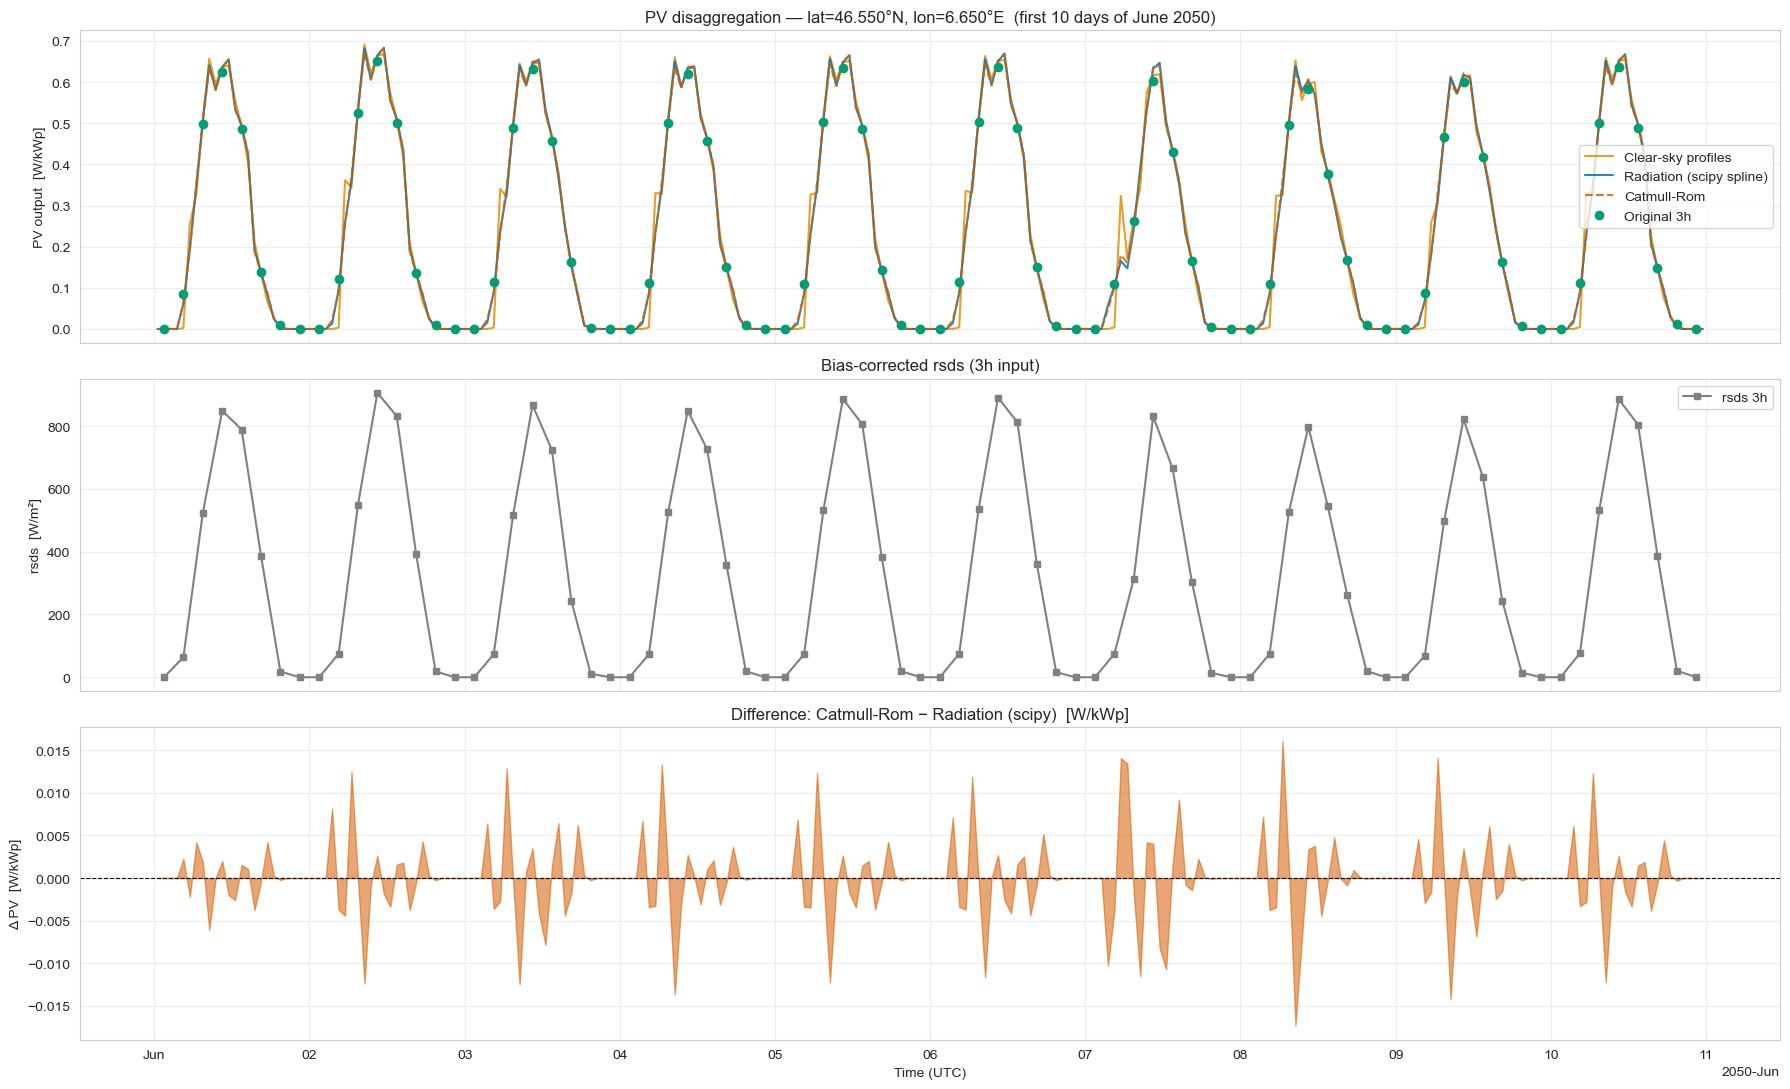

In [25]:
# --- Three-way PV time-series comparison at one grid point ---
n_days_plot = 10
t0_plot = pd.Timestamp(str(pv_3h_june.time.values[0])).floor("D")
t1_plot = t0_plot + pd.Timedelta(days=n_days_plot)

pv_cr_pt  = pv_1h_cr.isel(lat=i_lat, lon=i_lon).sel(time=slice(t0_plot, t1_plot))
pv_cs_pt2 = pv_1h_cs.isel(lat=i_lat, lon=i_lon).sel(time=slice(t0_plot, t1_plot))
pv_rad_pt2= pv_1h_rad.isel(lat=i_lat, lon=i_lon).sel(time=slice(t0_plot, t1_plot))
pv_3h_pt2 = pv_3h_june.isel(lat=i_lat, lon=i_lon).sel(time=slice(t0_plot, t1_plot)).compute()
rsds_pt2  = rsds_3h_june.isel(lat=i_lat, lon=i_lon).sel(time=slice(t0_plot, t1_plot)).compute()

fig, axes = plt.subplots(3, 1, figsize=(18, 11), sharex=True)

# PV comparison
ax = axes[0]
pv_cs_pt2.plot(ax=ax, lw=1.5, color="C1", alpha=0.85, label="Clear-sky profiles")
pv_rad_pt2.plot(ax=ax, lw=1.5, color="C0", alpha=0.85, label="Radiation (scipy spline)")
pv_cr_pt.plot(ax=ax, lw=1.5, color="C3", alpha=0.85, ls="--", label="Catmull-Rom")
pv_3h_pt2.plot(ax=ax, marker="o", ms=6, lw=0, color="C2",
               label="Original 3h", zorder=5)
ax.set_title(
    f"PV disaggregation — lat={float(pv_3h_june.lat.isel(lat=i_lat)):.3f}°N, "
    f"lon={float(pv_3h_june.lon.isel(lon=i_lon)):.3f}°E  "
    f"(first {n_days_plot} days of June 2050)",
    fontsize=12,
)
ax.legend(fontsize=10)
ax.set_xlabel("")
ax.set_ylabel("PV output  [W/kWp]")

# rsds
ax2 = axes[1]
rsds_pt2.plot(ax=ax2, marker="s", ms=4, lw=1.5, color="grey", label="rsds 3h")
ax2.set_title("Bias-corrected rsds (3h input)")
ax2.legend(fontsize=10)
ax2.set_xlabel("")
ax2.set_ylabel("rsds  [W/m²]")

# Difference: Catmull-Rom − scipy radiation
ax3 = axes[2]
common_t = np.intersect1d(pv_cr_pt.time.values, pv_rad_pt2.time.values)
diff_cr_rad = (pv_cr_pt.sel(time=common_t).values
               - pv_rad_pt2.sel(time=common_t).values)
ax3.fill_between(common_t, diff_cr_rad, alpha=0.55, color="C3")
ax3.axhline(0, color="k", lw=0.8, ls="--")
ax3.set_title("Difference: Catmull-Rom − Radiation (scipy)  [W/kWp]")
ax3.set_xlabel("Time (UTC)")
ax3.set_ylabel("Δ PV  [W/kWp]")

plt.tight_layout()
plt.show()


Energy conservation — relative error over 5×5 grid, June 2050:
  Clear-sky profiles  — max: +7.743e-07%  mean: -2.482e-08%
  Radiation (scipy)   — max: +1.120e-13%  mean: -2.584e-03%
  Catmull-Rom         — max: +3.478e-07%  mean: -1.462e-03%


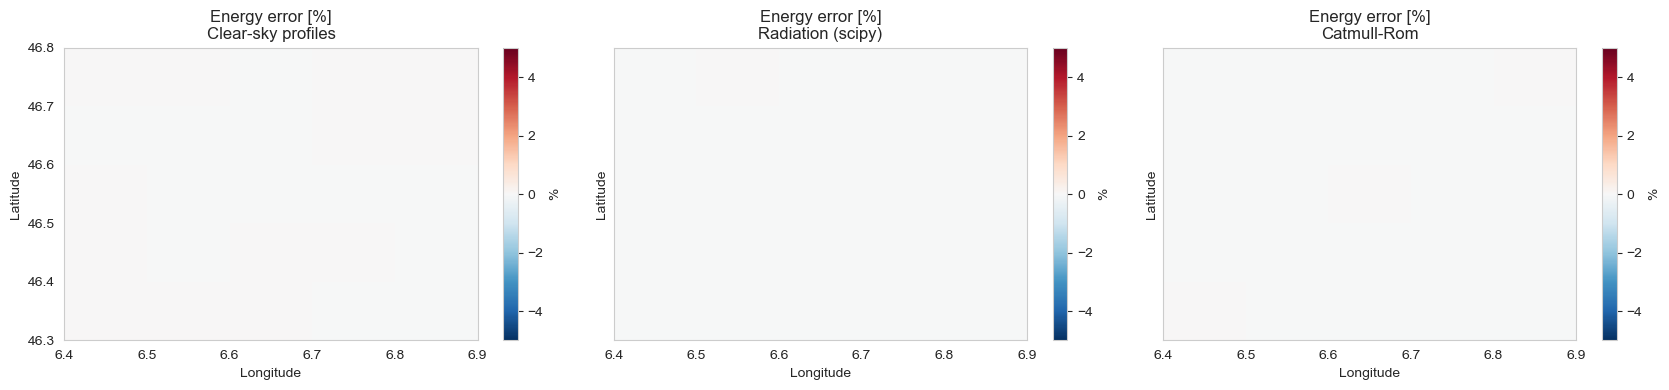

In [26]:
# --- Energy conservation: all three methods vs original 3h input ---
e3h_full = (pv_3h_june * 3).sum("time").compute()

def _energy_err(pv_1h):
    e = pv_1h.sum("time").compute()
    e = e.sel(lat=e3h_full.lat, lon=e3h_full.lon, method="nearest")
    return (e - e3h_full) / e3h_full.where(e3h_full > 0) * 100

rel_cs  = _energy_err(pv_1h_cs)
rel_rad = _energy_err(pv_1h_rad)
rel_cr  = _energy_err(pv_1h_cr)

print("Energy conservation — relative error over 5×5 grid, June 2050:")
print(f"  Clear-sky profiles  — max: {float(rel_cs.max()):+.3e}%  mean: {float(rel_cs.mean()):+.3e}%")
print(f"  Radiation (scipy)   — max: {float(rel_rad.max()):+.3e}%  mean: {float(rel_rad.mean()):+.3e}%")
print(f"  Catmull-Rom         — max: {float(rel_cr.max()):+.3e}%  mean: {float(rel_cr.mean()):+.3e}%")

fig, axes = plt.subplots(1, 3, figsize=(17, 4), sharey=True)
for ax, err, title in zip(
    axes,
    [rel_cs, rel_rad, rel_cr],
    ["Clear-sky profiles", "Radiation (scipy)", "Catmull-Rom"],
):
    im = ax.pcolormesh(err.lon, err.lat, err, cmap="RdBu_r", vmin=-5, vmax=5)
    ax.set_title(f"Energy error [%]\n{title}")
    ax.set_xlabel("Longitude")
    ax.set_ylabel("Latitude")
    plt.colorbar(im, ax=ax, label="%")
plt.tight_layout()
plt.show()


In [27]:
# --- Summary comparison table: Clear-sky vs Radiation (scipy) vs Catmull-Rom ---

methods = ["Clear-sky profiles", "Radiation (scipy spline)", "Catmull-Rom (local)"]

# Energy conservation: relative error over full 5×5 grid, June 2050
e3h = (pv_3h_june * 3).sum("time").compute()
def _rel_err(pv_1h):
    e1h = pv_1h.sum("time").compute()
    e1h = e1h.sel(lat=e3h.lat, lon=e3h.lon, method="nearest")
    err = (e1h - e3h) / e3h.where(e3h > 0) * 100
    return float(err.max()), float(err.mean())

errs = [_rel_err(pv_1h_cs), _rel_err(pv_1h_rad), _rel_err(pv_1h_cr)]

# Peak-hour agreement relative to radiation (scipy) as reference
def _peak_hour_agree(pv_1h_test, pv_1h_ref, i_lat, i_lon):
    def _peak(pv_1h):
        s = pv_1h.isel(lat=i_lat, lon=i_lon).to_series()
        return s.groupby(s.index.date).apply(
            lambda x: x.idxmax().hour if x.max() > 0 else np.nan
        )
    pref = _peak(pv_1h_ref)
    ptest = _peak(pv_1h_test)
    common = pref.index.intersection(ptest.index)
    diff = (ptest.loc[common].values.astype(float)
            - pref.loc[common].values.astype(float))
    non_nan = ~np.isnan(diff)
    return (diff[non_nan] == 0).mean() * 100  # % agreement

agree_vs_rad = [
    _peak_hour_agree(pv_1h_cs,  pv_1h_rad, i_lat, i_lon),
    100.0,
    _peak_hour_agree(pv_1h_cr,  pv_1h_rad, i_lat, i_lon),
]

df_summary = pd.DataFrame({
    "Method"                        : methods,
    "Energy err — max [%]"          : [f"{e[0]:+.3e}" for e in errs],
    "Energy err — mean [%]"         : [f"{e[1]:+.3e}" for e in errs],
    "Peak-hour agree vs rad [%]"    : [f"{a:.1f}" for a in agree_vs_rad],
    "Dask-compatible"               : ["✓", "✗ (global spline)", "✓"],
})
df_summary.set_index("Method", inplace=True)
print(df_summary.to_string())


                         Energy err — max [%] Energy err — mean [%] Peak-hour agree vs rad [%]    Dask-compatible
Method                                                                                                           
Clear-sky profiles                 +7.743e-07            -2.482e-08                       50.0                  ✓
Radiation (scipy spline)           +1.120e-13            -2.584e-03                      100.0  ✗ (global spline)
Catmull-Rom (local)                +3.478e-07            -1.462e-03                       76.7                  ✓


## pandas - Example Sursee

In [16]:
df_climate_model_2050 = pd.read_csv(path_energy_ch / "nexus-e" / "typical_2050_CH_Sursee_220.csv")
df_observed_year_pv = pd.read_csv(path_energy_ch / "nexus-e" / "CH_Sursee_220.csv")
df_observed_year_pv["time"] = np.arange(len(df_observed_year_pv))

### Get profiles

In [18]:
# Normalize PV values for each day in df_observed_year_pv
# Assumes 'time' is an integer index representing hour of year (0..8759)

# Compute day of year for each row
df_observed_year_pv['dayofyear'] = (df_observed_year_pv.index // 24) + 1

# Columns to normalize (exclude 'time' and 'dayofyear')
pv_columns = [col for col in df_observed_year_pv.columns if col not in ['time', 'dayofyear']]

# Group by day and normalize each PV column
df_profiles_observed_year = df_observed_year_pv.copy()
df_profiles_observed_year[pv_columns] = df_observed_year_pv.groupby('dayofyear')[pv_columns].transform(lambda x: x / x.sum())

In [19]:
# 1. Convert CH1903 coordinates to WGS84
x_ch1903, y_ch1903 = 651787, 226434
transformer = Transformer.from_crs("epsg:2056", "epsg:4326", always_xy=True)
lon, lat = transformer.transform(x_ch1903, y_ch1903)

# 2. Extract azimuth and tilt combinations from df_observed_year_pv
pv_columns = [col for col in df_observed_year_pv.columns if col not in ['time', 'dayofyear']]
azimuth_tilt_combos = []
for col in pv_columns:
    parts = col.split('tilt-')[-1].split("_")
    tilt = int(parts[0])
    azimuth = parts[-1]
    azimuth_tilt_combos.append((tilt, azimuth))

# 3. Generate all profiles and build output DataFrame
profiles_dict = {}
for tilt, azimuth_str in azimuth_tilt_combos:
    azimuth = azimuths[azimuth_str]
    profile_df = fast_generate_all_profiles_pd([lat], [lon], tilt, azimuth)
    profile_flat = profile_df.xs((lat, lon), level=('lat', 'lon')).reset_index()
    profiles_dict[f'tilt-{tilt}_{azimuth_str}'] = profile_flat.sort_values('time')['profile'].values

# 4. Build final DataFrame
n_hours = 365 * 24
df_profiles_clear_sky = pd.DataFrame({'time': np.arange(n_hours)})
for col, values in profiles_dict.items():
    df_profiles_clear_sky[col] = values

df_profiles_clear_sky.head()

,time,tilt-3_N,tilt-8_N,tilt-15_N,tilt-25_N,tilt-35_N,tilt-45_N,tilt-60_N,tilt-80_N,tilt-3_E,...,tilt-60_SW,tilt-80_SW,tilt-3_W,tilt-8_W,tilt-15_W,tilt-25_W,tilt-35_W,tilt-45_W,tilt-60_W,tilt-80_W
0,0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1,1,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2,2,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
3,3,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
4,4,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


<Axes: title={'center': 'Normalized Clear-sky PV Profiles for Tilt-45_N'}>

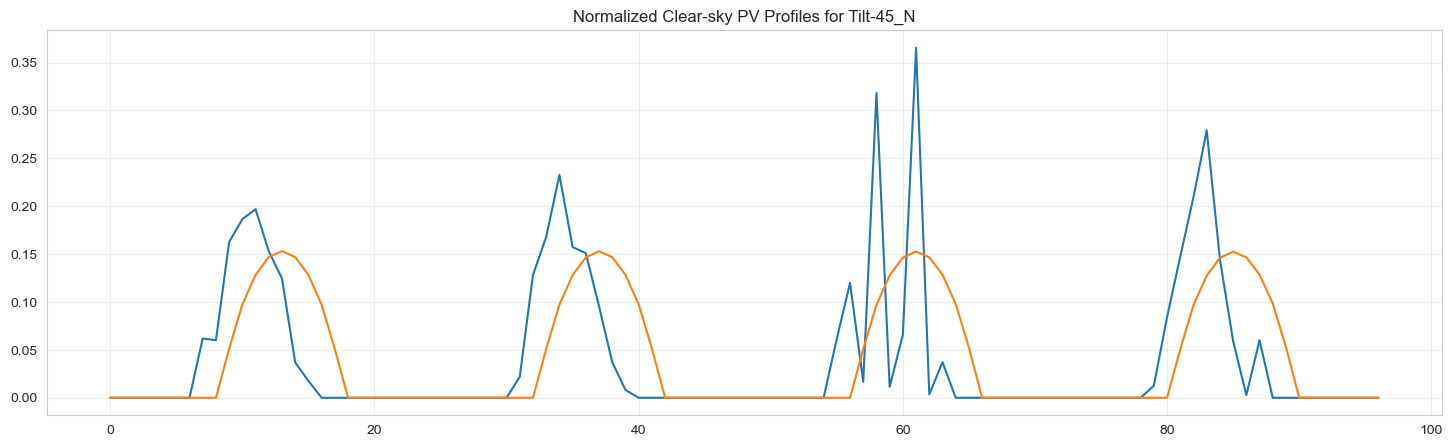

In [20]:
df_profiles_observed_year["tilt-45_N"].loc[0:96].plot(figsize=(18, 5), title="Normalized PV Profiles for Tilt-45_N")
df_profiles_clear_sky["tilt-45_N"].loc[0:96].plot(figsize=(18, 5), title="Normalized Clear-sky PV Profiles for Tilt-45_N")

### Test on one config

In [ ]:
pv_3h_df = df_climate_model_2050[['time', "tilt-45_N"]].copy()
pv_3h_df.rename(columns={"tilt-45_N": 'pv'}, inplace=True)

# Disaggregate using observed year profiles
df_out_observed = disaggregate_pv_to_hourly_pd(pv_3h_df, df_profiles_observed_year, "tilt-45_N")
df_out_observed['time'] = df_out_observed['time'] - pd.Timedelta(minutes=30)
df_out_observed


,time,pv_hourly
0,2048-01-01 00:00:00,0.0
1,2048-01-01 01:00:00,0.0
2,2048-01-01 02:00:00,0.0
3,2048-01-01 03:00:00,0.0
4,2048-01-01 04:00:00,0.0
...,...,...
8755,2048-12-31 19:00:00,0.0
8756,2048-12-31 20:00:00,0.0
8757,2048-12-31 21:00:00,0.0
8758,2048-12-31 22:00:00,0.0


In [ ]:
pv_3h_df = df_climate_model_2050[['time', "tilt-45_N"]].copy()
pv_3h_df.rename(columns={"tilt-45_N": 'pv'}, inplace=True)

# Disaggregate using clear-sky profiles
df_out_clear_sky = disaggregate_pv_to_hourly_pd(pv_3h_df, df_profiles_clear_sky, "tilt-45_N")
df_out_clear_sky['time'] = df_out_clear_sky['time'] - pd.Timedelta(minutes=30)
df_out_clear_sky


,time,pv_hourly
0,2048-01-01 00:00:00,0.0
1,2048-01-01 01:00:00,0.0
2,2048-01-01 02:00:00,0.0
3,2048-01-01 03:00:00,0.0
4,2048-01-01 04:00:00,0.0
...,...,...
8755,2048-12-31 19:00:00,0.0
8756,2048-12-31 20:00:00,0.0
8757,2048-12-31 21:00:00,0.0
8758,2048-12-31 22:00:00,0.0


In [23]:
# Replicate each 3-hourly value into 3 consecutive hourly values
pv_3h_df_hourly = pv_3h_df.copy()
pv_3h_df_hourly['time'] = pd.to_datetime(pv_3h_df_hourly['time'])

hourly_records = []
for idx, row in pv_3h_df_hourly.iterrows():
    center_time = row['time']
    pv_val = row['pv']
    # Generate times: center-1h, center, center+1h
    for offset in [-1, 0, 1]:
        hourly_time = center_time + pd.Timedelta(hours=offset)
        hourly_records.append({'time': hourly_time, 'pv_hourly': pv_val})

df_pv_hourly_replicated = pd.DataFrame(hourly_records)
df_pv_hourly_replicated['time'] = df_pv_hourly_replicated['time'] - pd.Timedelta(minutes=30)

Text(0.5, 0, 'Time')

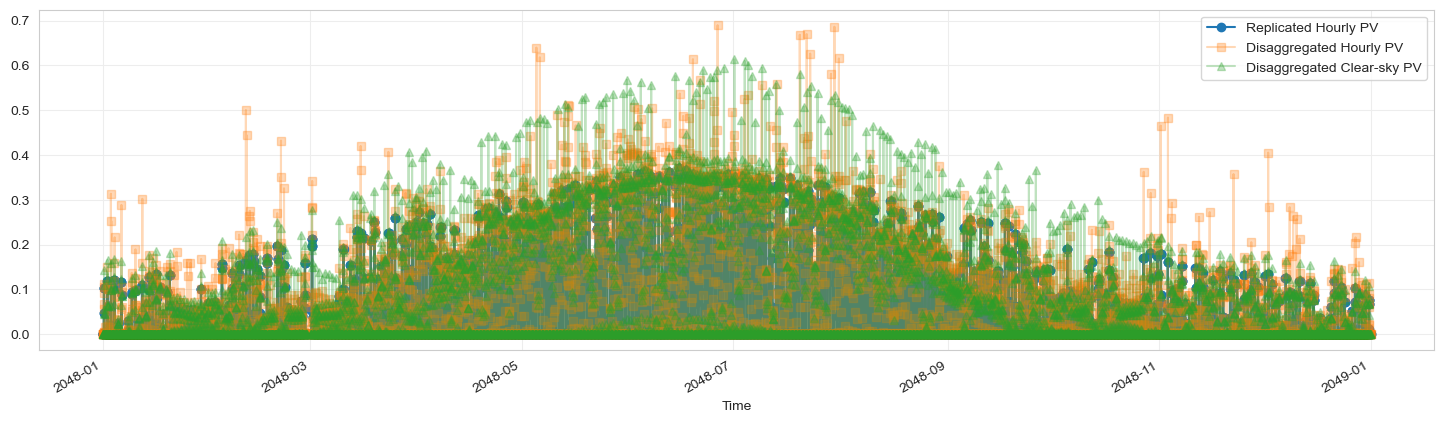

In [24]:
fig, ax = plt.subplots(figsize=(18, 5))
df_pv_hourly_replicated.plot(x='time', y='pv_hourly', label='Replicated Hourly PV', marker='o', ax=ax)
df_out_observed.plot(x='time', y='pv_hourly', label='Disaggregated Hourly PV', marker='s', ax=ax, alpha=0.3)
df_out_clear_sky.plot(x='time', y='pv_hourly', label='Disaggregated Clear-sky PV', marker='^', ax=ax, alpha=0.3)
ax.set_xlabel('Time')

### Apply to all configs

In [ ]:
results_observed = []
results_clear_sky = []
pv_columns = [col for col in df_observed_year_pv.columns if col not in ['time', 'dayofyear']]

for col in pv_columns:
    print(f"Processing config: {col}")
    # Prepare input DataFrame for disaggregation
    pv_3h_df = df_climate_model_2050[['time', col]].copy()
    pv_3h_df.rename(columns={col: 'pv'}, inplace=True)

    # Disaggregate using observed year profiles
    df_out_observed = disaggregate_pv_to_hourly_pd(pv_3h_df, df_profiles_observed_year, col)
    df_out_observed.rename(columns={'pv_hourly': col}, inplace=True)
    df_out_observed['time'] = df_out_observed['time'] - pd.Timedelta(minutes=30)
    results_observed.append(df_out_observed[['time', col]])

    # Disaggregate using clear-sky profiles
    df_out_clear = disaggregate_pv_to_hourly_pd(pv_3h_df, df_profiles_clear_sky, col)
    df_out_clear.rename(columns={'pv_hourly': col}, inplace=True)
    df_out_clear['time'] = df_out_clear['time'] - pd.Timedelta(minutes=30)
    results_clear_sky.append(df_out_clear[['time', col]])

df_observed_all = pd.concat(results_observed, axis=1)
df_clear_sky_all = pd.concat(results_clear_sky, axis=1)

df_observed_all = df_observed_all.loc[:, ~df_observed_all.columns.duplicated()]
df_clear_sky_all = df_clear_sky_all.loc[:, ~df_clear_sky_all.columns.duplicated()]


Processing config: tilt-3_N
Processing config: tilt-8_N
Processing config: tilt-15_N
Processing config: tilt-25_N
Processing config: tilt-35_N
Processing config: tilt-45_N
Processing config: tilt-60_N
Processing config: tilt-80_N
Processing config: tilt-3_E
Processing config: tilt-8_E
Processing config: tilt-15_E
Processing config: tilt-25_E
Processing config: tilt-35_E
Processing config: tilt-45_E
Processing config: tilt-60_E
Processing config: tilt-80_E
Processing config: tilt-3_SE
Processing config: tilt-8_SE
Processing config: tilt-15_SE
Processing config: tilt-25_SE
Processing config: tilt-35_SE
Processing config: tilt-45_SE
Processing config: tilt-60_SE
Processing config: tilt-80_SE
Processing config: tilt-3_S
Processing config: tilt-8_S
Processing config: tilt-15_S
Processing config: tilt-25_S
Processing config: tilt-35_S
Processing config: tilt-45_S
Processing config: tilt-60_S
Processing config: tilt-80_S
Processing config: tilt-3_SW
Processing config: tilt-8_SW
Processing con

In [ ]:
df_observed_all.to_csv(path_energy_ch / "nexus-e" / "observed_profile_pv_hourly.csv", index=False)
df_clear_sky_all.to_csv(path_energy_ch / "nexus-e" / "clear_sky_profile_pv_hourly.csv", index=False)

### Analysis and comparison

In [26]:
annual_sum_observed = df_observed_all.drop('time', axis=1).sum()
annual_sum_clear = df_clear_sky_all.drop('time', axis=1).sum()

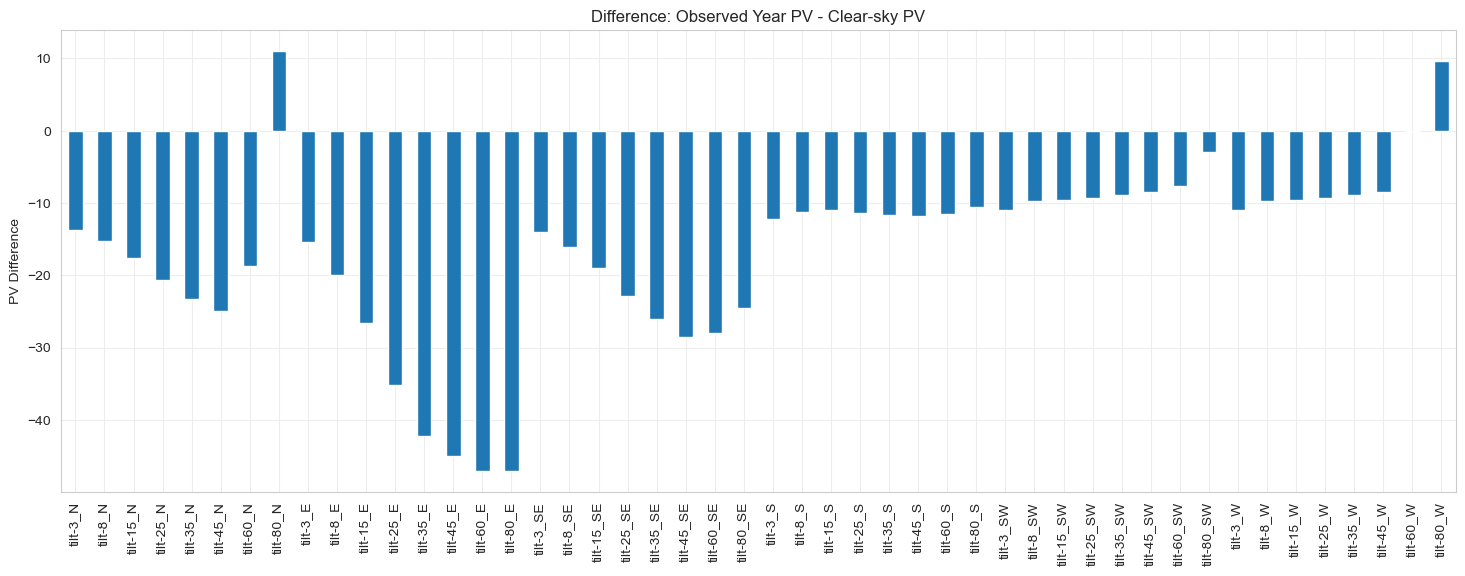

In [27]:
diff = annual_sum_clear - annual_sum_observed
diff.plot.bar(figsize=(18, 6), title="Difference: Observed Year PV - Clear-sky PV")
plt.ylabel("PV Difference")
plt.show()

In [28]:
df_observed_all['month'] = pd.to_datetime(df_observed_all['time']).dt.month
df_clear_sky_all['month'] = pd.to_datetime(df_clear_sky_all['time']).dt.month

monthly_sum_observed = df_observed_all.drop('time', axis=1).groupby('month').sum()
monthly_sum_clear = df_clear_sky_all.drop('time', axis=1).groupby('month').sum()

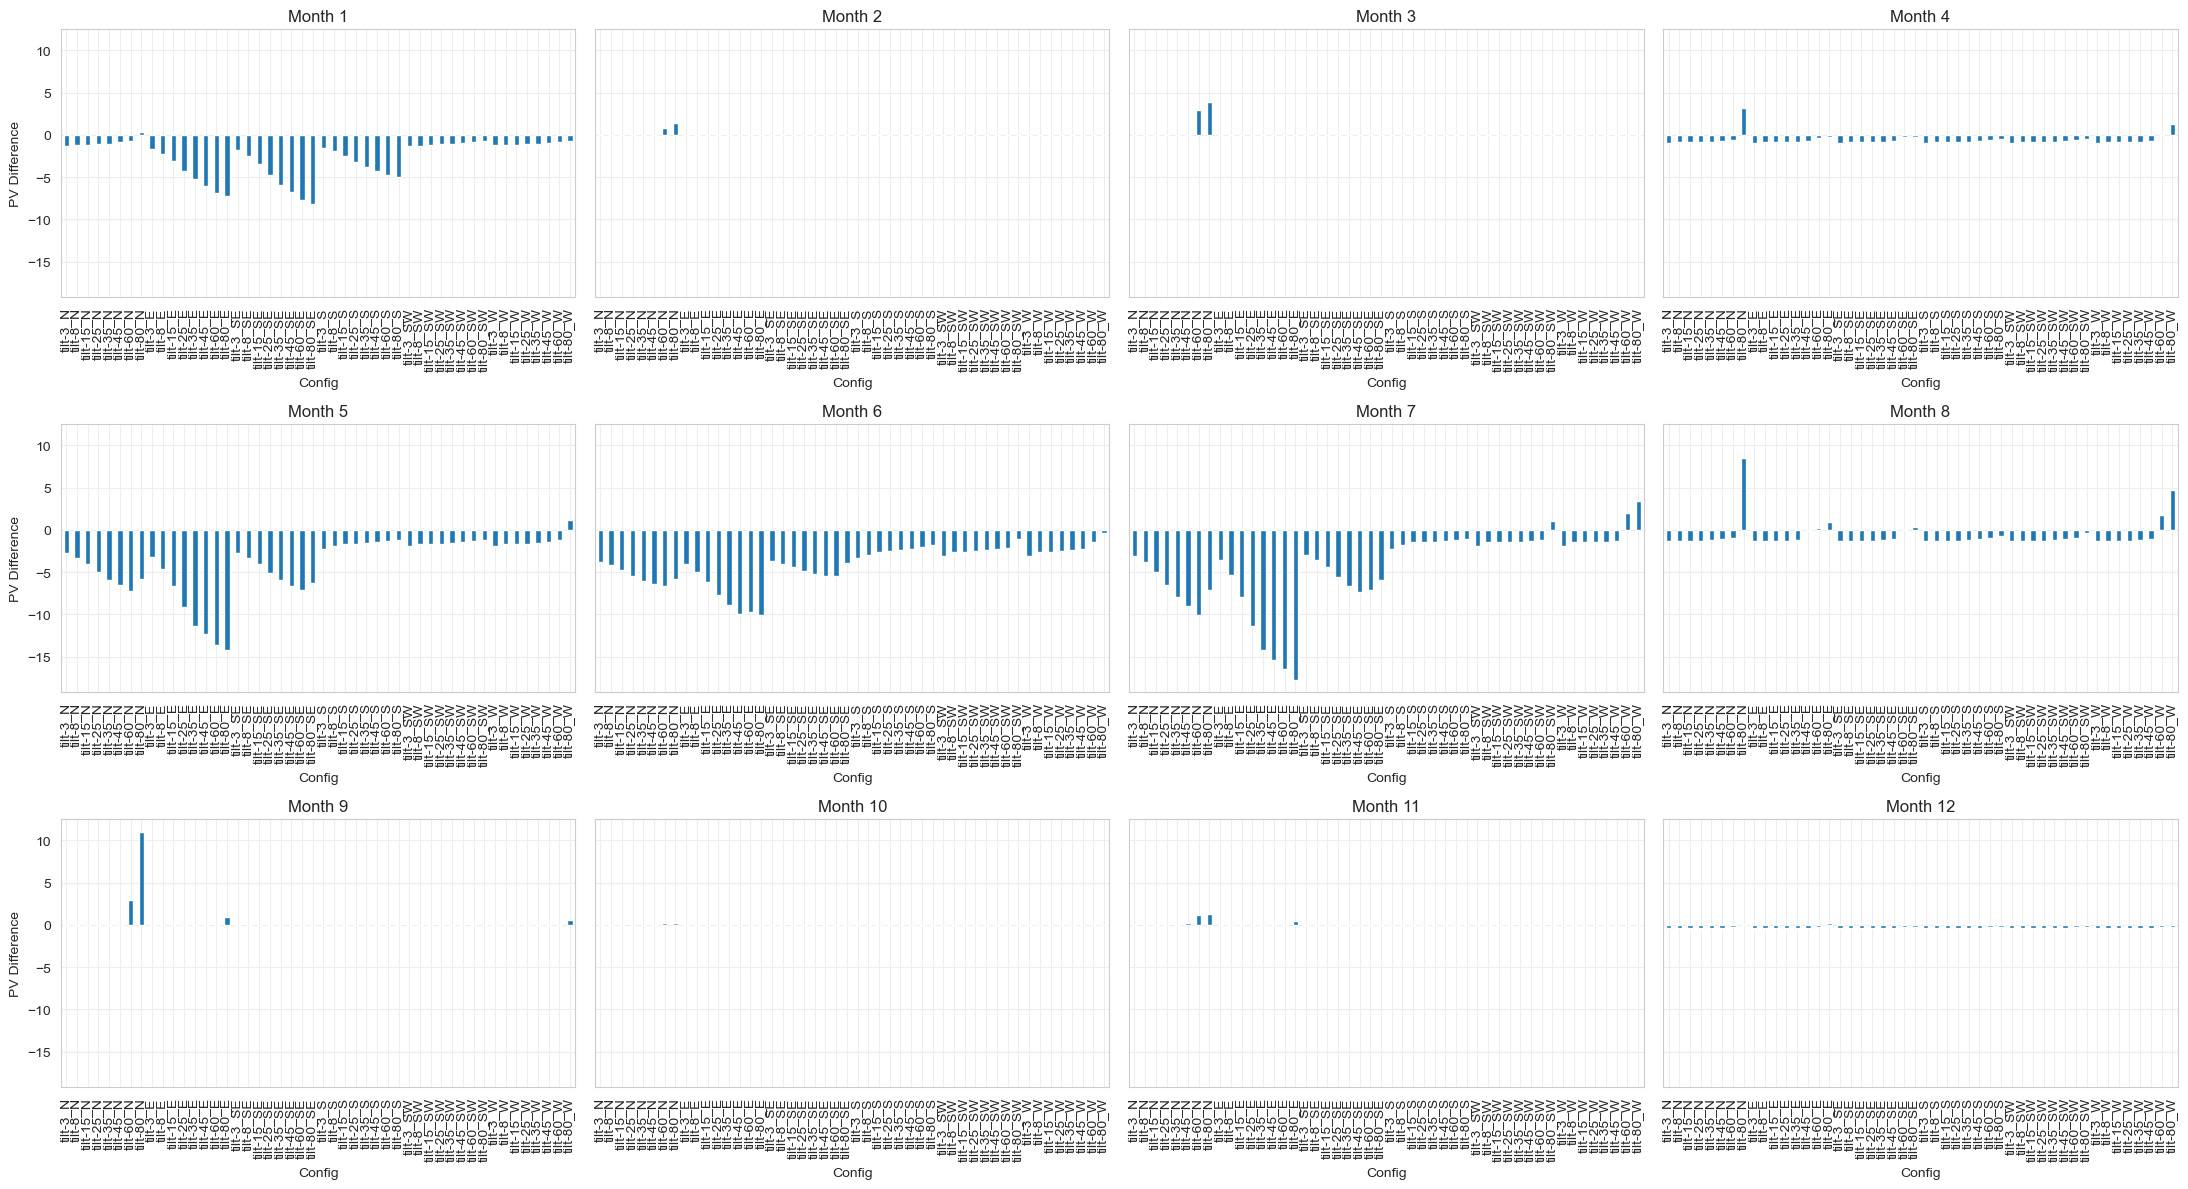

In [29]:
fig, axes = plt.subplots(3, 4, figsize=(22, 12), sharey=True)
months = range(1, 13)

for i, month in enumerate(months):
    ax = axes.flat[i]
    diff_month = monthly_sum_clear.loc[month] - monthly_sum_observed.loc[month]
    diff_month.plot.bar(ax=ax)
    ax.set_title(f"Month {month}")
    ax.set_xlabel("Config")
    ax.set_ylabel("PV Difference" if i % 4 == 0 else "")
    ax.tick_params(axis='x', labelrotation=90)

plt.tight_layout()
plt.show()

In [30]:
def mode_peak_hour(df):
    df['hour'] = pd.to_datetime(df['time']).dt.hour
    df['dayofyear'] = df.index // 24 + 1
    peak_hours = {}
    for col in df.columns:
        if col in ['time', 'month', 'dayofyear', 'hour']:
            continue
        # For each month, find the most frequent hour of daily peak
        monthly_peaks = df.groupby(['month', 'dayofyear'])[[col, 'hour']].apply(
            lambda x: x[[col, 'hour']].sort_values(col, ascending=False).iloc[0]['hour']
        )
        peak_hours[col] = monthly_peaks.groupby('month').agg(lambda x: x.mode().iloc[0])
    return pd.DataFrame(peak_hours)

peak_hour_observed_mode = mode_peak_hour(df_observed_all)
peak_hour_clear_mode = mode_peak_hour(df_clear_sky_all)

In [31]:
peak_hour_observed_mode

,tilt-3_N,tilt-8_N,tilt-15_N,tilt-25_N,tilt-35_N,tilt-45_N,tilt-60_N,tilt-80_N,tilt-3_E,tilt-8_E,...,tilt-60_SW,tilt-80_SW,tilt-3_W,tilt-8_W,tilt-15_W,tilt-25_W,tilt-35_W,tilt-45_W,tilt-60_W,tilt-80_W
month,,,,,,,,,,,,,,,,,,,,,
1,11.0,11.0,11.0,12.0,11.0,11.0,11.0,10.0,11.0,11.0,...,12.0,12.0,12.0,12.0,12.0,12.0,12.0,12.0,12.0,14.0
2,12.0,12.0,11.0,11.0,8.0,8.0,8.0,11.0,11.0,11.0,...,12.0,12.0,12.0,12.0,12.0,12.0,12.0,12.0,12.0,15.0
3,11.0,11.0,11.0,11.0,8.0,12.0,11.0,11.0,11.0,11.0,...,12.0,12.0,11.0,12.0,12.0,12.0,12.0,12.0,15.0,15.0
4,12.0,11.0,11.0,12.0,11.0,12.0,9.0,9.0,12.0,11.0,...,13.0,13.0,12.0,12.0,12.0,12.0,13.0,13.0,13.0,13.0
5,12.0,12.0,12.0,12.0,11.0,12.0,5.0,5.0,12.0,11.0,...,12.0,12.0,12.0,12.0,12.0,12.0,12.0,13.0,14.0,15.0
6,11.0,11.0,11.0,11.0,11.0,11.0,5.0,5.0,11.0,11.0,...,12.0,12.0,11.0,12.0,12.0,12.0,12.0,12.0,14.0,14.0
7,11.0,11.0,11.0,11.0,11.0,5.0,5.0,5.0,11.0,10.0,...,12.0,11.0,11.0,11.0,12.0,12.0,12.0,12.0,14.0,15.0
8,12.0,12.0,11.0,11.0,11.0,11.0,9.0,6.0,11.0,12.0,...,12.0,13.0,12.0,12.0,12.0,12.0,12.0,14.0,14.0,15.0
9,12.0,12.0,12.0,11.0,11.0,8.0,11.0,6.0,12.0,12.0,...,13.0,15.0,12.0,12.0,12.0,12.0,15.0,15.0,15.0,15.0


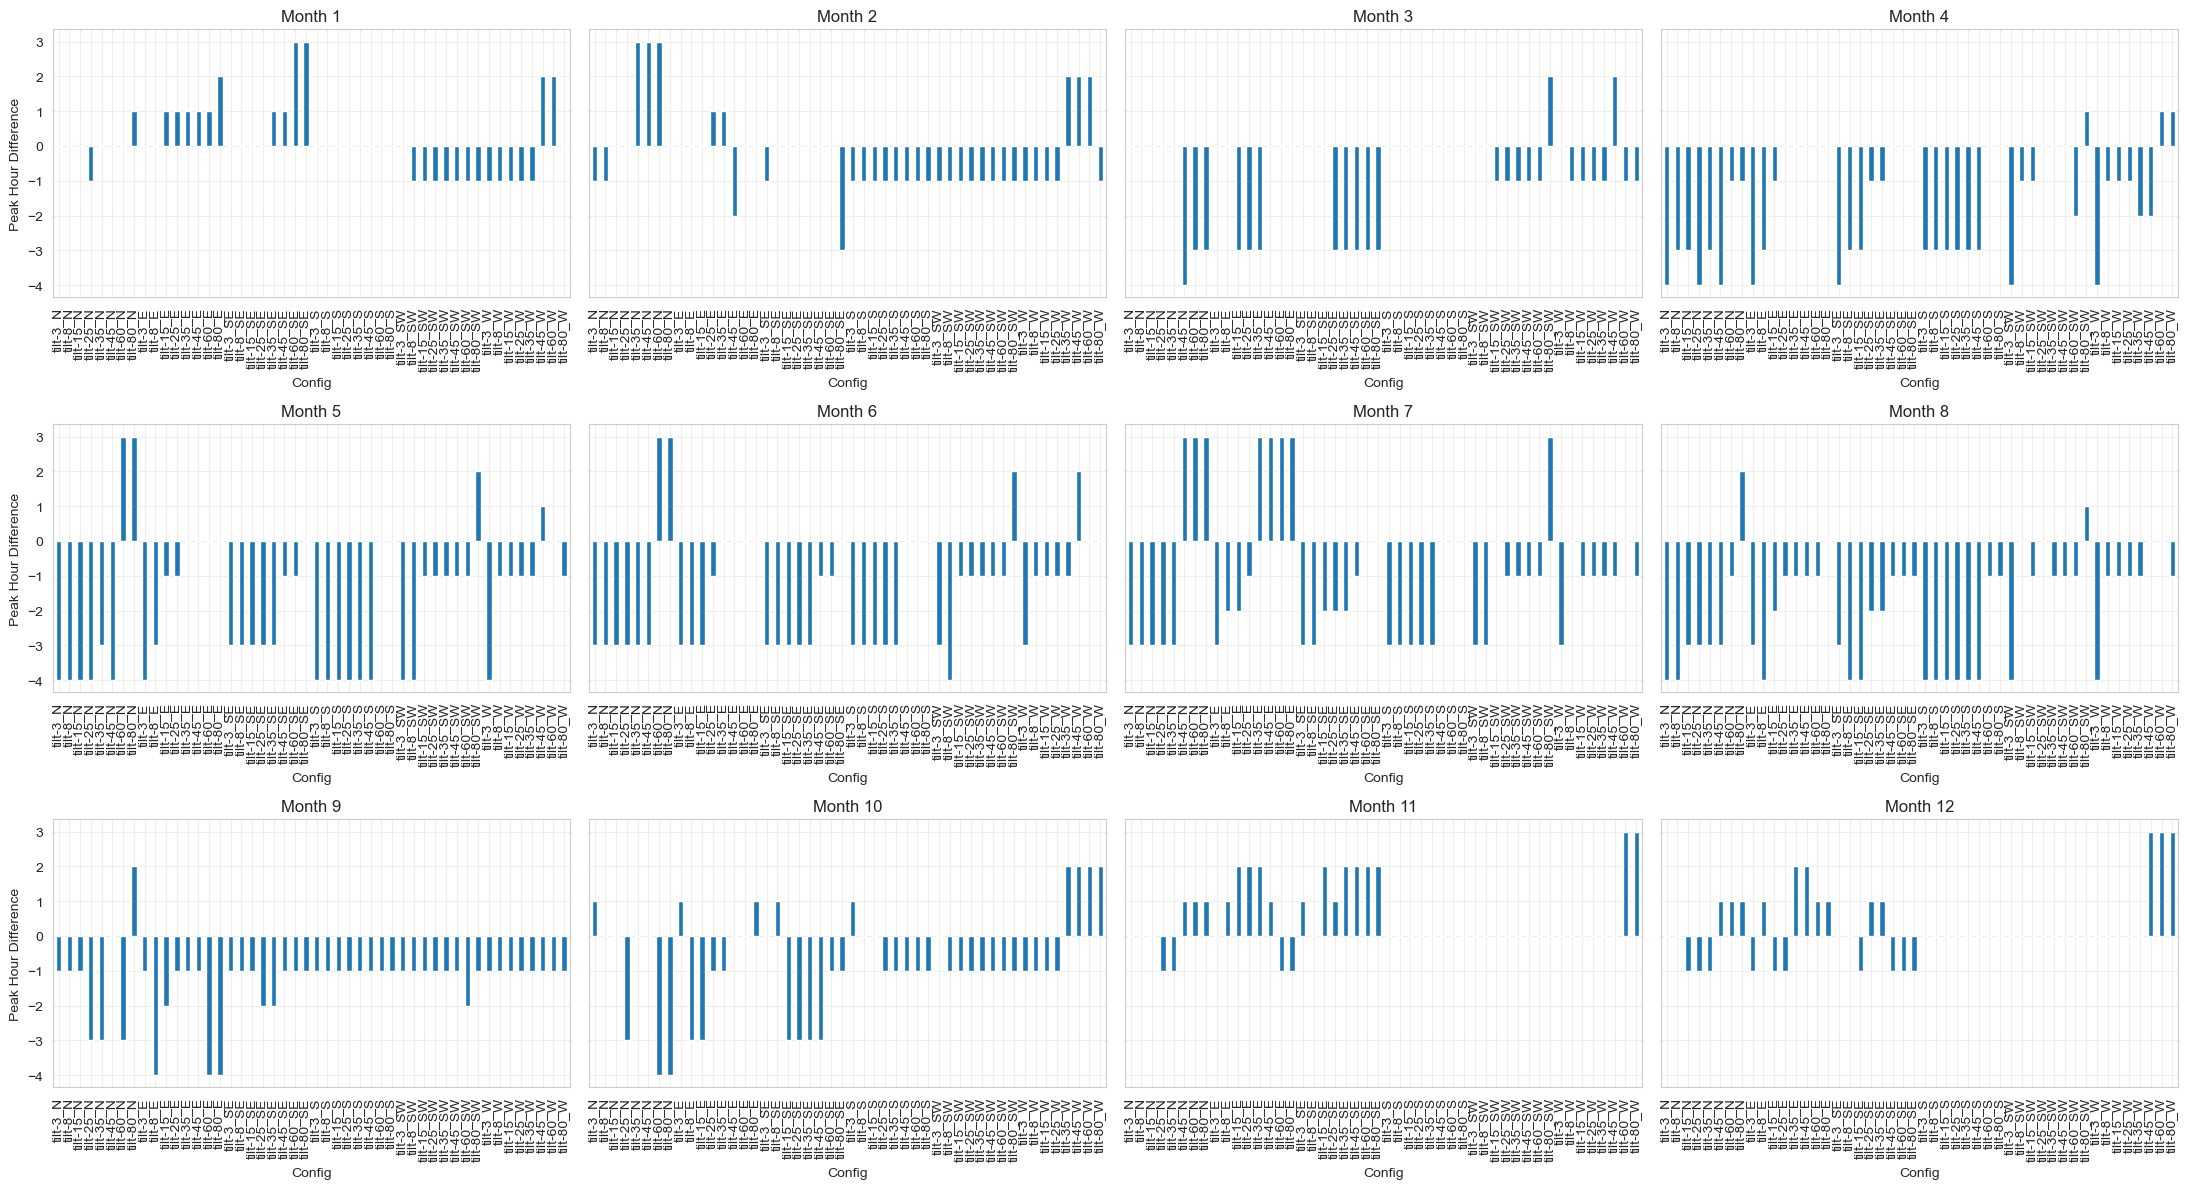

In [32]:
fig, axes = plt.subplots(3, 4, figsize=(22, 12), sharey=True)
months = range(1, 13)

for i, month in enumerate(months):
    ax = axes.flat[i]
    diff_month = peak_hour_clear_mode.loc[month] - peak_hour_observed_mode.loc[month]
    diff_month.plot.bar(ax=ax)
    ax.set_title(f"Month {month}")
    ax.set_xlabel("Config")
    ax.set_ylabel("Peak Hour Difference" if i % 4 == 0 else "")
    ax.tick_params(axis='x', labelrotation=90)

plt.tight_layout()
plt.show()

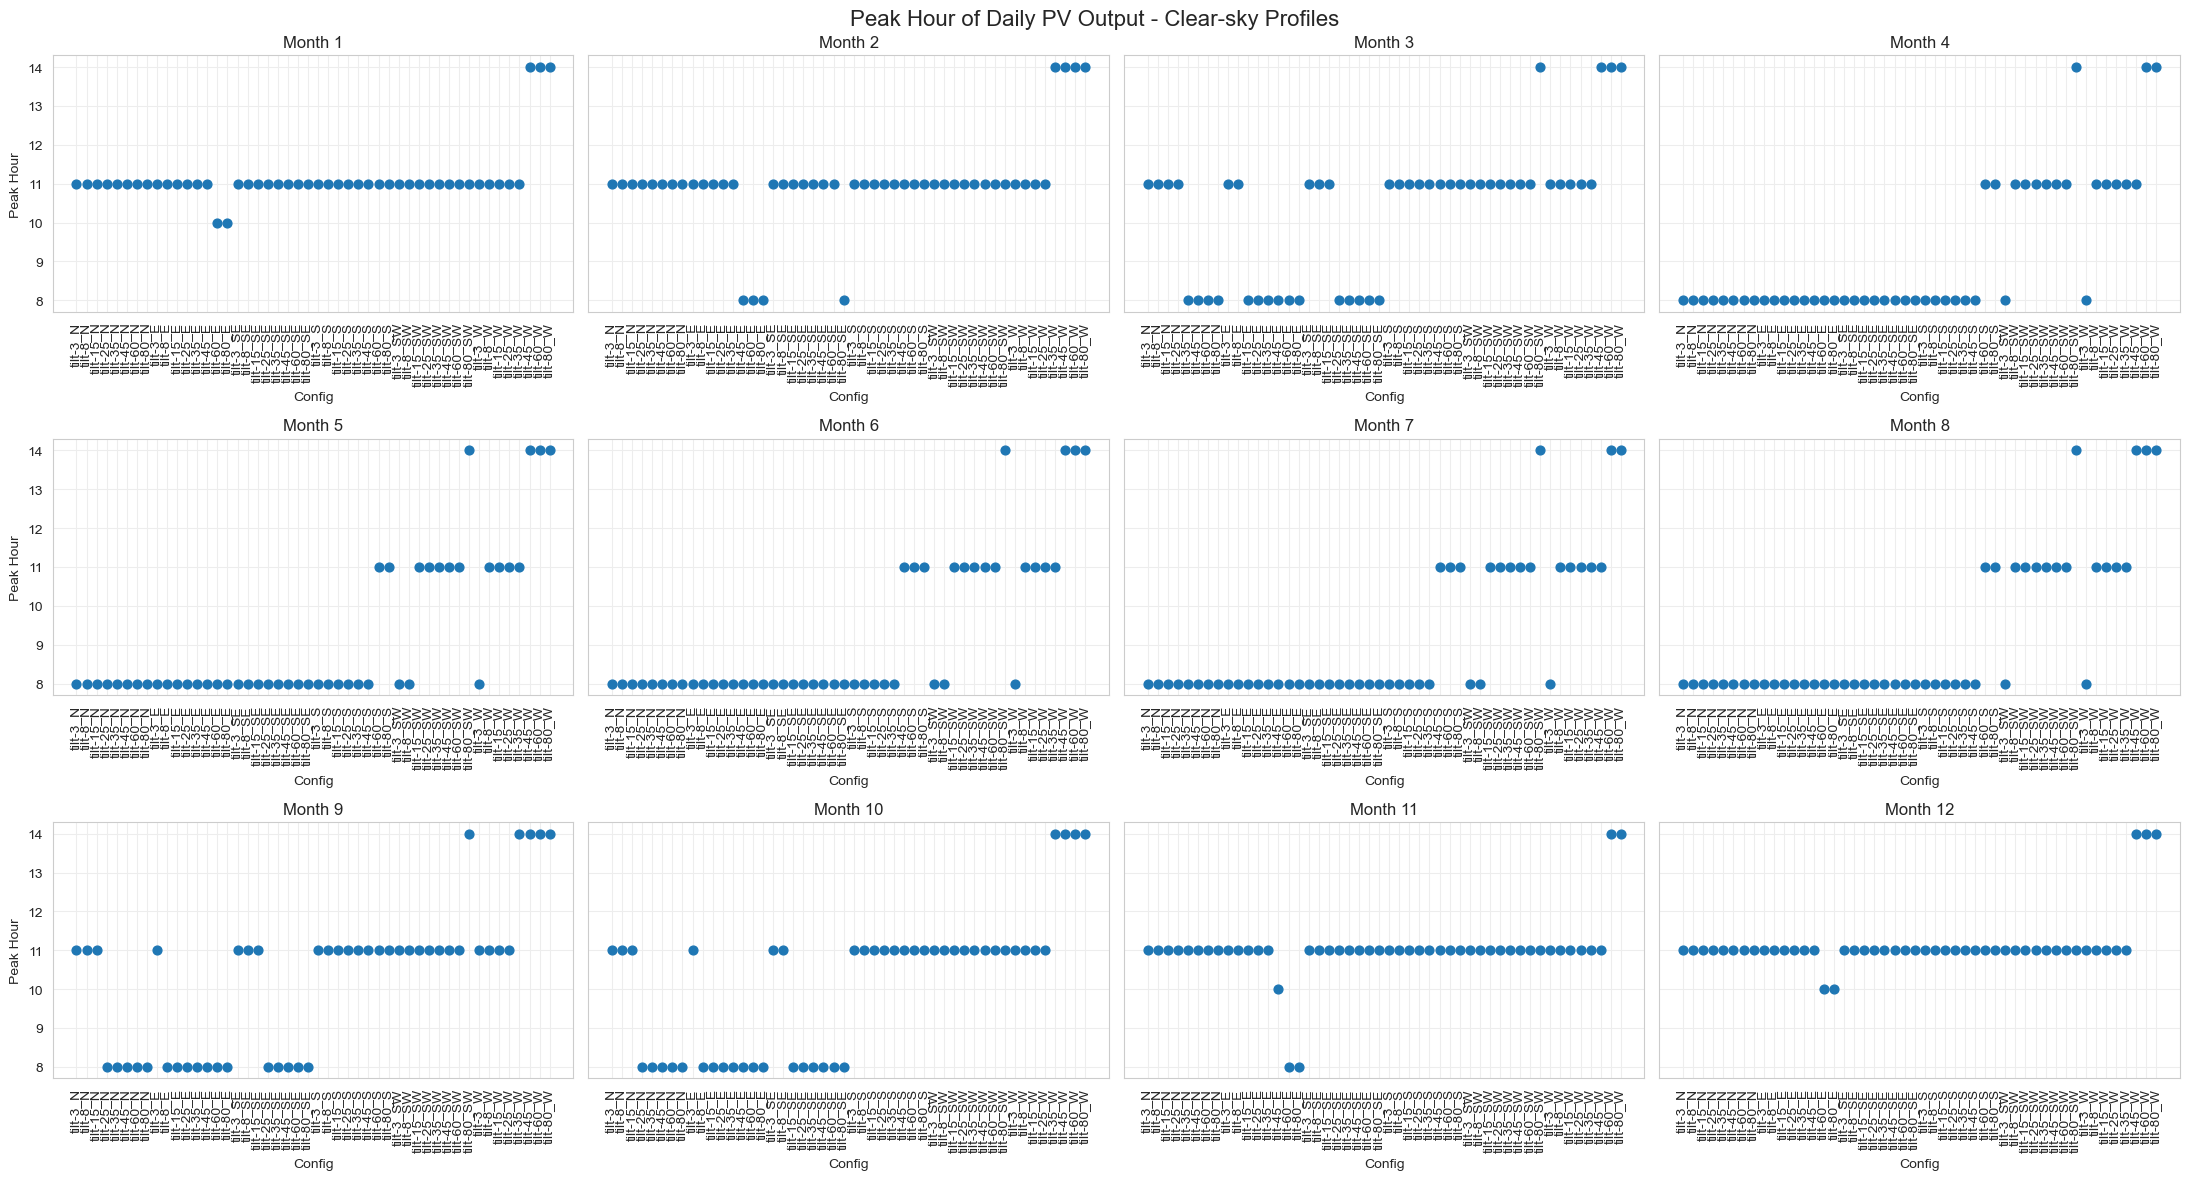

In [38]:
fig, axes = plt.subplots(3, 4, figsize=(22, 12), sharey=True)
months = range(1, 13)

for i, month in enumerate(months):
    ax = axes.flat[i]
    ax.scatter(peak_hour_clear_mode.columns, peak_hour_clear_mode.loc[month], color='C0', s=40)
    ax.set_title(f"Month {month}")
    ax.set_xlabel("Config")
    ax.set_ylabel("Peak Hour" if i % 4 == 0 else "")
    ax.tick_params(axis='x', labelrotation=90)

plt.suptitle("Peak Hour of Daily PV Output - Clear-sky Profiles", fontsize=16)
plt.tight_layout()
plt.show()

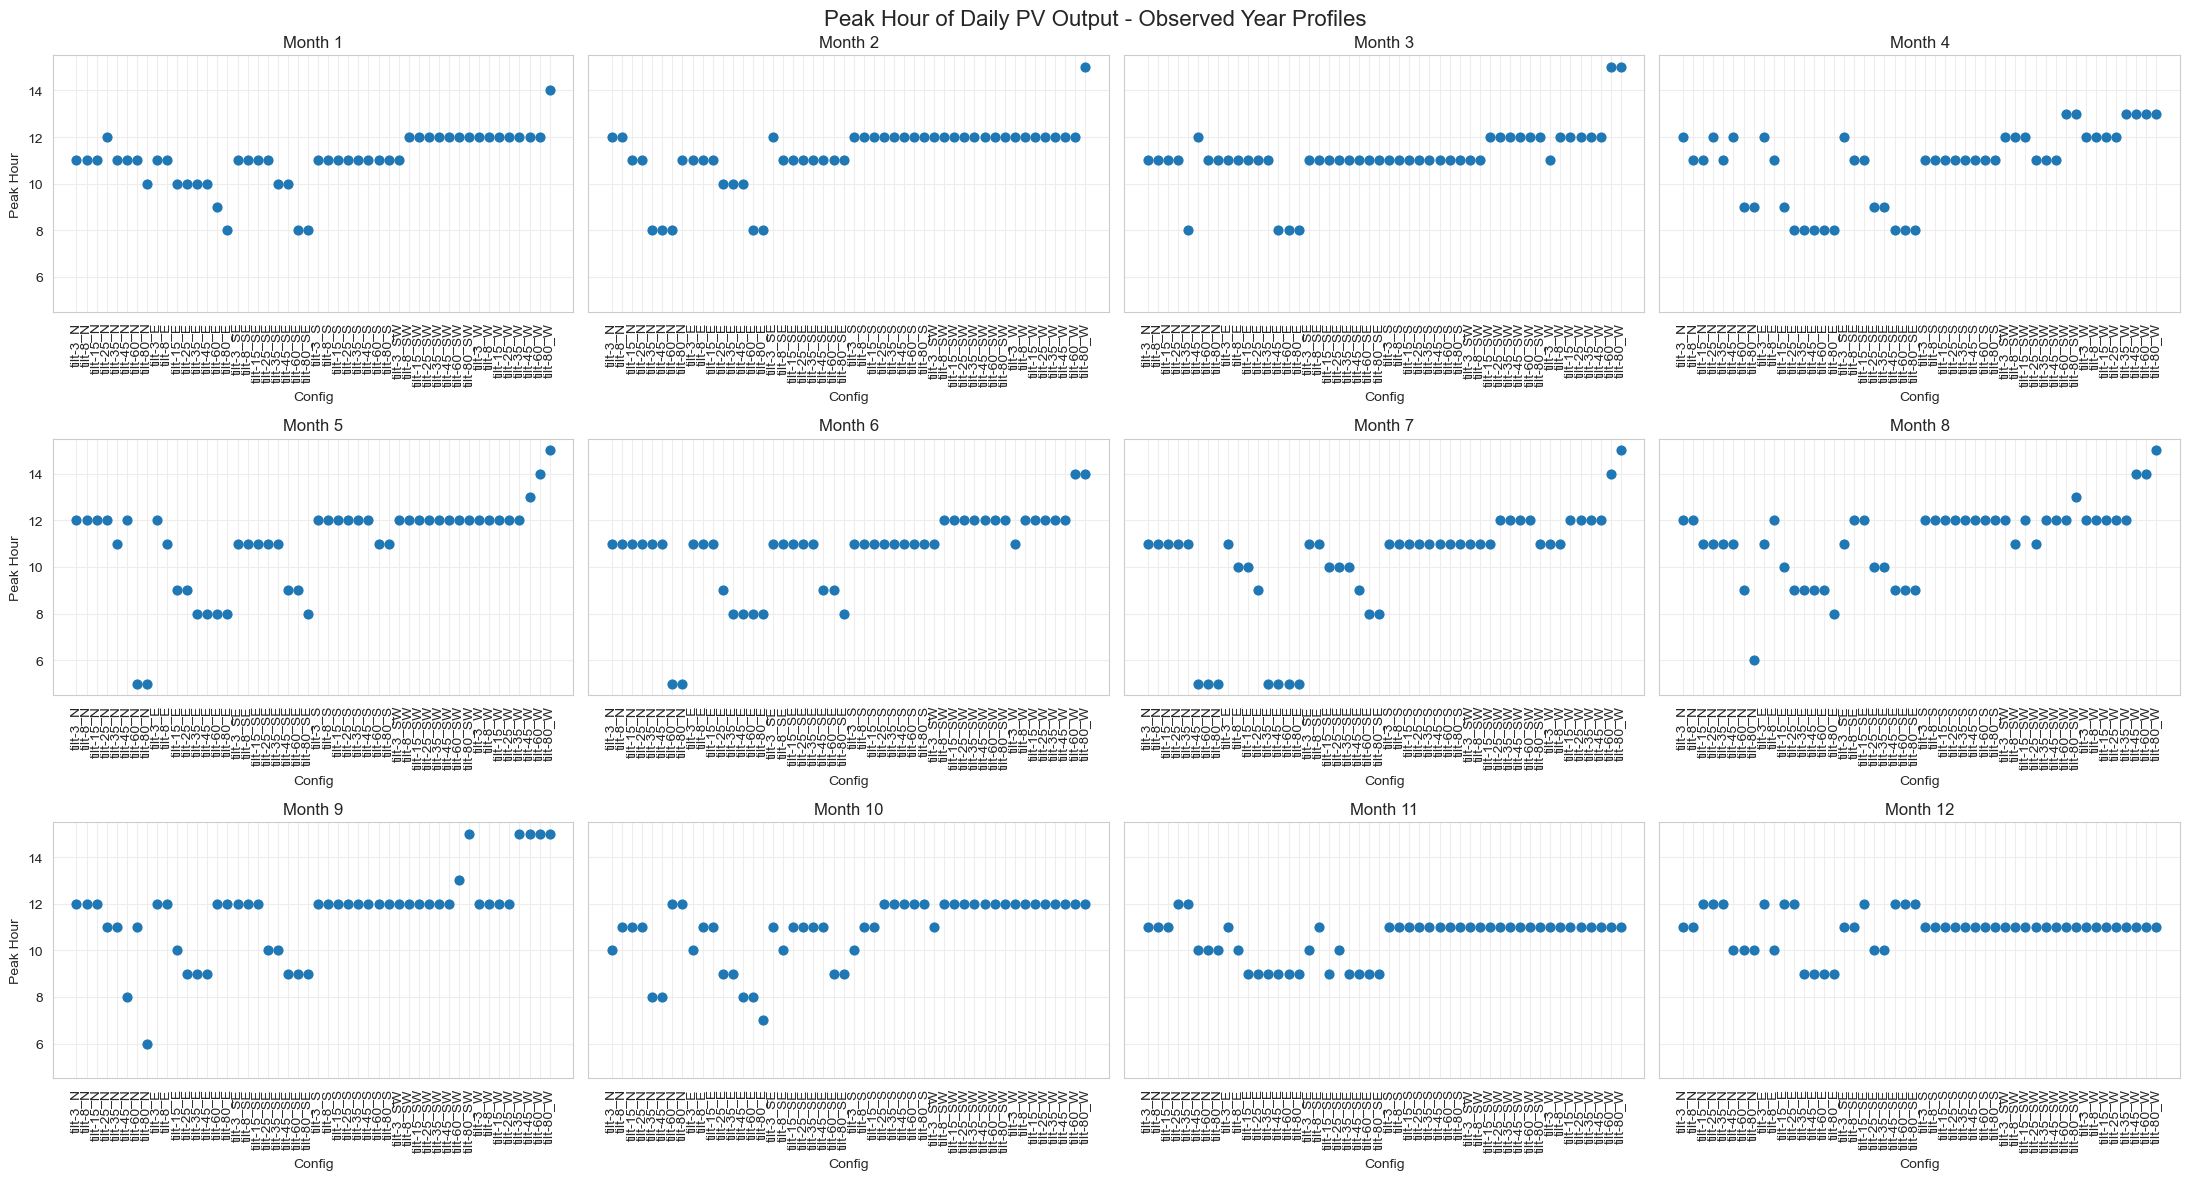

In [39]:
fig, axes = plt.subplots(3, 4, figsize=(22, 12), sharey=True)
months = range(1, 13)

for i, month in enumerate(months):
    ax = axes.flat[i]
    ax.scatter(peak_hour_observed_mode.columns, peak_hour_observed_mode.loc[month], color='C0', s=40)
    ax.set_title(f"Month {month}")
    ax.set_xlabel("Config")
    ax.set_ylabel("Peak Hour" if i % 4 == 0 else "")
    ax.tick_params(axis='x', labelrotation=90)

plt.suptitle("Peak Hour of Daily PV Output - Observed Year Profiles", fontsize=16)
plt.tight_layout()
plt.show()